# Projeto Lego

In [45]:
# Carregar os dados da URL no Pandas
import pandas as pd
url = 'https://raw.githubusercontent.com/KeithGalli/lego-analysis/master/datasets/lego_sets.csv'
df = pd.read_csv(url)

### Carregar bases de dados adicionais do Rebrickable

Aqui vamos carregar as tabelas relacionais do Rebrickable diretamente das fontes compactadas (`.csv.gz`) usando o Pandas.

In [46]:
import pandas as pd

# URLs dos principais arquivos disponibilizados pelo Rebrickable
urls = {
    'themes': 'https://cdn.rebrickable.com/media/downloads/themes.csv.gz',
    'sets': 'https://cdn.rebrickable.com/media/downloads/sets.csv.gz',
    'parts': 'https://cdn.rebrickable.com/media/downloads/parts.csv.gz',
    'inventories': 'https://cdn.rebrickable.com/media/downloads/inventories.csv.gz',
    'inventory_parts': 'https://cdn.rebrickable.com/media/downloads/inventory_parts.csv.gz',
    'colors': 'https://cdn.rebrickable.com/media/downloads/colors.csv.gz',
    'part_categories': 'https://cdn.rebrickable.com/media/downloads/part_categories.csv.gz',
    'elements': 'https://cdn.rebrickable.com/media/downloads/elements.csv.gz',
    'part_relationships': 'https://cdn.rebrickable.com/media/downloads/part_relationships.csv.gz',
    'minifigs': 'https://cdn.rebrickable.com/media/downloads/minifigs.csv.gz',
    'inventory_minifigs': 'https://cdn.rebrickable.com/media/downloads/inventory_minifigs.csv.gz',
    'inventory_sets': 'https://cdn.rebrickable.com/media/downloads/inventory_sets.csv.gz'
}

# Dicionário para armazenar os DataFrames
dataframes = {}

for name, url in urls.items():
    try:
        print(f"Carregando {name}...")
        # O pandas lida automaticamente com a descompressão de arquivos .gz
        dataframes[name] = pd.read_csv(url)
        print(f"{name.capitalize()} carregado com sucesso! Shape: {dataframes[name].shape}")
    except Exception as e:
        print(f"Erro ao carregar {name}: {e}")

# Exemplo de exibição de um dos datasets
if 'themes' in dataframes:
    display(dataframes['themes'].head())

Carregando themes...
Themes carregado com sucesso! Shape: (496, 3)
Carregando sets...
Sets carregado com sucesso! Shape: (28544, 6)
Carregando parts...
Parts carregado com sucesso! Shape: (64897, 4)
Carregando inventories...
Inventories carregado com sucesso! Shape: (47789, 3)
Carregando inventory_parts...
Inventory_parts carregado com sucesso! Shape: (1567180, 6)
Carregando colors...
Colors carregado com sucesso! Shape: (275, 8)
Carregando part_categories...
Part_categories carregado com sucesso! Shape: (76, 2)
Carregando elements...
Elements carregado com sucesso! Shape: (114661, 4)
Carregando part_relationships...
Part_relationships carregado com sucesso! Shape: (37535, 3)
Carregando minifigs...
Minifigs carregado com sucesso! Shape: (17293, 4)
Carregando inventory_minifigs...
Inventory_minifigs carregado com sucesso! Shape: (25903, 3)
Carregando inventory_sets...
Inventory_sets carregado com sucesso! Shape: (5217, 3)


,id,name,parent_id
0,1,Technic,NaN
1,3,Competition,1.0
2,4,Expert Builder,1.0
3,16,RoboRiders,1.0
4,17,Speed Slammers,1.0


In [47]:
dataframes['minifigs'].sample


<bound method NDFrame.sample of           fig_num                                               name  \
0      fig-000001                                 Toy Store Employee   
1      fig-000002                                       Customer Kid   
2      fig-000003                              Assassin Droid, White   
3      fig-000004           Man, White Torso, Black Legs, Brown Hair   
4      fig-000005                    Captain America with Short Legs   
...           ...                                                ...   
17288  fig-018220                           LEGO Store Hangzhou, Man   
17289  fig-018221                         LEGO Store Hangzhou, Woman   
17290  fig-018222       Pizzaria Waiter, White Torso, Warm Pink Legs   
17291  fig-018223  Woman, Light Bluish Grey/Bright Green Wetsuit,...   
17292  fig-018224               Kid Adventurer, Dark Brown Suit, Hat   

       num_parts                                            img_url  
0              4  https://cdn.rebrickable.com/media/sets/fig-000...  
1              4  https://cdn.rebrickable.com/media/sets/fig-000...  
2              8  https://cdn.rebrickable.com/media/sets/fig-000...  
3              4  https://cdn.rebrickable.com/media/sets/fig-000...  
4              3  https://cdn.rebrickable.com/media/sets/fig-000...  
...          ...                                                ...  
17288          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17289          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17290          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17291          4  https://cdn.rebrickable.com/media/sets/fig-018...  
17292          4  https://cdn.rebrickable.com/media/sets/fig-018...  

[17293 rows x 4 columns]>

### Salvar DataFrames no Formato Parquet

Vamos iterar sobre o dicionário `dataframes` e salvar cada um deles como um arquivo `.parquet` de forma individual.

In [48]:
import os

# Criar um diretório para organizar os arquivos parquet
os.makedirs('lego_parquet', exist_ok=True)

for name, df in dataframes.items():
    try:
        output_path = f'lego_parquet/{name}.parquet'
        # Salva o DataFrame no formato Parquet (requer pyarrow ou fastparquet instalado)
        df.to_parquet(output_path, index=False)
        print(f"DataFrame '{name}' salvo com sucesso em: {output_path} (Tamanho: {os.path.getsize(output_path) / (1024*1024):.2f} MB)")
    except Exception as e:
        print(f"Erro ao salvar {name} em parquet: {e}")

DataFrame 'themes' salvo com sucesso em: lego_parquet/themes.parquet (Tamanho: 0.01 MB)
DataFrame 'sets' salvo com sucesso em: lego_parquet/sets.parquet (Tamanho: 0.84 MB)
DataFrame 'parts' salvo com sucesso em: lego_parquet/parts.parquet (Tamanho: 1.86 MB)
DataFrame 'inventories' salvo com sucesso em: lego_parquet/inventories.parquet (Tamanho: 0.61 MB)
DataFrame 'inventory_parts' salvo com sucesso em: lego_parquet/inventory_parts.parquet (Tamanho: 17.20 MB)
DataFrame 'colors' salvo com sucesso em: lego_parquet/colors.parquet (Tamanho: 0.01 MB)
DataFrame 'part_categories' salvo com sucesso em: lego_parquet/part_categories.parquet (Tamanho: 0.00 MB)
DataFrame 'elements' salvo com sucesso em: lego_parquet/elements.parquet (Tamanho: 1.70 MB)
DataFrame 'part_relationships' salvo com sucesso em: lego_parquet/part_relationships.parquet (Tamanho: 0.37 MB)
DataFrame 'minifigs' salvo com sucesso em: lego_parquet/minifigs.parquet (Tamanho: 0.56 MB)
DataFrame 'inventory_minifigs' salvo com sucess

In [49]:
!ls -l lego_parquet/


total 23992
-rw-r--r-- 1 root root    13542 Oct 17 22:12 colors.parquet
-rw-r--r-- 1 root root  1780580 Oct 17 22:12 elements.parquet
-rw-r--r-- 1 root root   642553 Oct 17 22:12 inventories.parquet
-rw-r--r-- 1 root root   215834 Oct 17 22:12 inventory_minifigs.parquet
-rw-r--r-- 1 root root 18038814 Oct 17 22:12 inventory_parts.parquet
-rw-r--r-- 1 root root    43421 Oct 17 22:12 inventory_sets.parquet
-rw-r--r-- 1 root root   588898 Oct 17 22:12 minifigs.parquet
-rw-r--r-- 1 root root     3233 Oct 17 22:12 part_categories.parquet
-rw-r--r-- 1 root root   386783 Oct 17 22:12 part_relationships.parquet
-rw-r--r-- 1 root root  1945516 Oct 17 22:12 parts.parquet
-rw-r--r-- 1 root root   879157 Oct 17 22:12 sets.parquet
-rw-r--r-- 1 root root    10615 Oct 17 22:12 themes.parquet


### Instalar e Configurar o PySpark

Instalamos a biblioteca do PySpark no ambiente do Google Colab.

In [50]:
!pip install pyspark

### Iniciar SparkSession e Carregar Parquets como RDDs

In [51]:
from pyspark.sql import SparkSession
import os

# Inicializa a sessão do Spark
spark = SparkSession.builder \
    .appName("AnaliseLego") \
    .getOrCreate()

# Pasta onde estão os parquets
parquet_dir = 'lego_parquet'
rdds = {}

# Carrega cada parquet como DataFrame do Spark e converte para RDD
for file_name in os.listdir(parquet_dir):
    if file_name.endswith('.parquet'):
        name = file_name.replace('.parquet', '')
        file_path = os.path.join(parquet_dir, file_name)

        try:
            # Carrega o arquivo Parquet como Spark DataFrame
            spark_df = spark.read.parquet(file_path)
            # Converte o DataFrame do Spark em RDD
            rdds[name] = spark_df.rdd
            print(f"Parquet '{name}' carregado e convertido para RDD com sucesso!")
        except Exception as e:
            print(f"Erro ao carregar {name}: {e}")

# Demonstração simples pegando um exemplo de registro do RDD 'themes'
if 'themes' in rdds:
    print("\nExemplo de registro no RDD 'themes':")
    print(rdds['themes'].take(5))

Parquet 'inventories' carregado e convertido para RDD com sucesso!
Parquet 'elements' carregado e convertido para RDD com sucesso!
Parquet 'parts' carregado e convertido para RDD com sucesso!
Parquet 'inventory_minifigs' carregado e convertido para RDD com sucesso!
Parquet 'minifigs' carregado e convertido para RDD com sucesso!
Parquet 'inventory_parts' carregado e convertido para RDD com sucesso!
Parquet 'colors' carregado e convertido para RDD com sucesso!
Parquet 'themes' carregado e convertido para RDD com sucesso!
Parquet 'part_relationships' carregado e convertido para RDD com sucesso!
Parquet 'inventory_sets' carregado e convertido para RDD com sucesso!
Parquet 'sets' carregado e convertido para RDD com sucesso!
Parquet 'part_categories' carregado e convertido para RDD com sucesso!

Exemplo de registro no RDD 'themes':
[Row(id=1, name='Technic', parent_id=None), Row(id=3, name='Competition', parent_id=1.0), Row(id=4, name='Expert Builder', parent_id=1.0), Row(id=16, name='RoboRi

### Criar Views Temporárias a partir dos RDDs para consultas SQL

Como os RDDs foram criados a partir de DataFrames lidos do Parquet, eles possuem a estrutura de `Row` com nomes de colunas definidos. Podemos convertê-los de volta para DataFrames do Spark e registrá-los como views SQL temporárias.

In [52]:
# Iterar sobre o dicionário de RDDs, recriar os DataFrames e registrá-los como views temporárias
for name, rdd in rdds.items():
    try:
        # Cria o DataFrame a partir do RDD
        spark_df_temp = spark.createDataFrame(rdd)
        # Registra como view temporária com o mesmo nome original
        spark_df_temp.createOrReplaceTempView(name)
        print(f"View temporária SQL '{name}' registrada com sucesso!")
    except Exception as e:
        print(f"Erro ao registrar a view SQL para {name}: {e}")

View temporária SQL 'inventories' registrada com sucesso!
View temporária SQL 'elements' registrada com sucesso!
View temporária SQL 'parts' registrada com sucesso!
View temporária SQL 'inventory_minifigs' registrada com sucesso!
View temporária SQL 'minifigs' registrada com sucesso!
View temporária SQL 'inventory_parts' registrada com sucesso!
View temporária SQL 'colors' registrada com sucesso!
View temporária SQL 'themes' registrada com sucesso!
View temporária SQL 'part_relationships' registrada com sucesso!
View temporária SQL 'inventory_sets' registrada com sucesso!
View temporária SQL 'sets' registrada com sucesso!
View temporária SQL 'part_categories' registrada com sucesso!


### Testar consultas Spark SQL

Agora você já pode executar consultas SQL diretamente nas tabelas usando `spark.sql()`!

## 1. Quantos conjuntos LEGO foram lançados por ano?

### Conceito

A análise temporal permite observar como a quantidade de conjuntos LEGO registrados varia ao longo dos anos. Essa informação ajuda a identificar períodos com maior volume de lançamentos e a compreender a evolução do catálogo disponível na base de dados.

### Explicação do código

Utilizamos o Spark SQL para agrupar os conjuntos pela coluna `year` e contar quantos registros existem em cada ano por meio da função `COUNT(*)`. Em seguida, ordenamos os resultados pela quantidade de conjuntos, em ordem decrescente, selecionando os dez anos com os maiores valores.

O resultado é convertido para Pandas para a construção de um gráfico de barras horizontais, facilitando a comparação entre os anos selecionados.

In [53]:
# Exemplo de query SQL: Contar a quantidade de sets por ano e ordenar decrescente
query_exemplo = """
SELECT year, COUNT(*) as total_sets
FROM sets
GROUP BY year
ORDER BY total_sets DESC
LIMIT 10
"""

resultado = spark.sql(query_exemplo)
resultado.show()

+----+----------+
|year|total_sets|
+----+----------+
|2026|      1556|
|2025|      1436|
|2023|      1406|
|2021|      1369|
|2022|      1368|
|2024|      1304|
|2019|      1143|
|2020|      1136|
|2017|      1122|
|2018|      1082|
+----+----------+



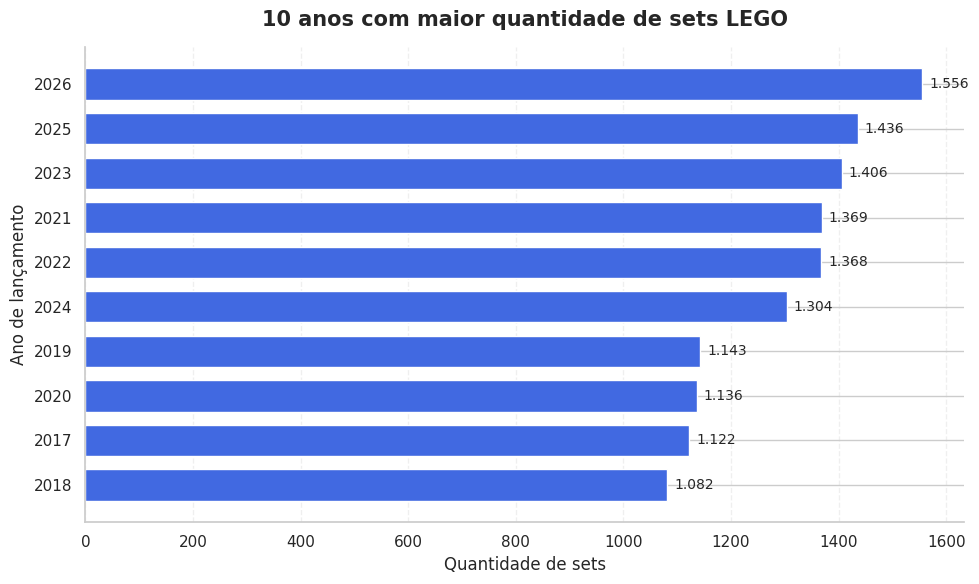

In [54]:

import matplotlib.pyplot as plt

# Converter o resultado do Spark para Pandas
df_grafico = resultado.toPandas()

# Garantir os tipos numéricos
df_grafico["year"] = df_grafico["year"].astype(int)
df_grafico["total_sets"] = df_grafico["total_sets"].astype(int)

# Ordenar do menor para o maior
df_grafico = df_grafico.sort_values("total_sets")

# Criar gráfico de barras horizontal
fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    df_grafico["year"].astype(str),
    df_grafico["total_sets"],
    color="#4169E1",
    height=0.7
)

# Adicionar os valores ao final das barras
ax.bar_label(
    barras,
    labels=[
        f"{valor:,}".replace(",", ".")
        for valor in df_grafico["total_sets"]
    ],
    padding=5,
    fontsize=10
)

ax.set_title(
    "10 anos com maior quantidade de sets LEGO",
    fontsize=15,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Quantidade de sets")
ax.set_ylabel("Ano de lançamento")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Conclusão

A análise permitiu identificar os anos com maior quantidade de conjuntos LEGO registrados na base de dados. No recorte apresentado, 2026 ocupa a primeira posição, seguido por 2025 e 2023. Portanto, a consulta responde à pergunta ao destacar os anos com mais registros, mas não permite concluir, isoladamente, que esses foram os anos de maior sucesso comercial ou de maior crescimento histórico da LEGO.

## 2. Quais conjuntos LEGO contêm a minifigura Darth Vader?

### Conceito

Esta análise busca identificar os conjuntos LEGO que incluem a minifigura Darth Vader. O objetivo é explorar o relacionamento entre conjuntos, inventários e minifiguras, utilizando as tabelas relacionais disponibilizadas pelo Rebrickable.

### Explicação do código

Utilizamos o Spark SQL para relacionar as tabelas `sets`, `inventories`, `inventory_minifigs` e `minifigs`. Os relacionamentos são realizados por meio dos identificadores dos conjuntos, dos inventários e das minifiguras.

A condição `LIKE '%Darth Vader%'` permite localizar registros cujo nome contém essa expressão. A utilização de `SELECT DISTINCT` evita que um mesmo conjunto apareça repetido no resultado final.

Após executar a consulta, convertemos os resultados para Pandas e selecionamos até 20 conjuntos para exibição no gráfico. As barras servem apenas para organizar visualmente os nomes dos conjuntos, não representando uma quantidade ou pontuação.

In [55]:
# Listar Darth Vader em minifigs
query_darth_vader = """
SELECT
  minifigs.fig_num,
  minifigs.name AS minifig_name
FROM minifigs
WHERE minifigs.name LIKE '%Darth Vader%'
"""

resultado_darth_vader = spark.sql(query_darth_vader)

In [56]:
# Quais os sets tem a minifig do Darth Vader?

query_set_com_darth_vader = """
SELECT DISTINCT
    s.set_num AS set_num,
    s.name AS set_name,
    s.year AS year
FROM sets s
JOIN inventories i
    ON s.set_num = i.set_num
JOIN inventory_minifigs im
    ON i.id = im.inventory_id
JOIN minifigs m
    ON im.fig_num = m.fig_num
WHERE m.name LIKE '%Darth Vader%'
"""

resultado_set_com_darth_vader = spark.sql(query_set_com_darth_vader)

resultado_set_com_darth_vader.show(truncate=False)

print("Total de sets encontrados:", resultado_set_com_darth_vader.count())



+---------------+---------------------------------------------+----+
|set_num        |set_name                                     |year|
+---------------+---------------------------------------------+----+
|852554-1       |Star Wars Magnet Set                         |2008|
|7965-1         |Millennium Falcon                            |2011|
|10123-1        |Cloud City                                   |2003|
|10131-1        |TIE Fighter Collection                       |2004|
|75261-1        |Clone Scout Walker - 20th Anniversary Edition|2019|
|75302-1        |Imperial Shuttle                             |2021|
|75296-1        |Darth Vader Meditation Chamber               |2021|
|9781837252169-1|Star Wars: The Dark Lord                     |2026|
|912408-2       |Darth Vader [Helmet Tin]                     |2024|
|5004607-1      |Darth Vader Buildable Watch                  |2015|
|10188-1        |Death Star                                   |2008|
|5002198-1      |Star Wars: The Em

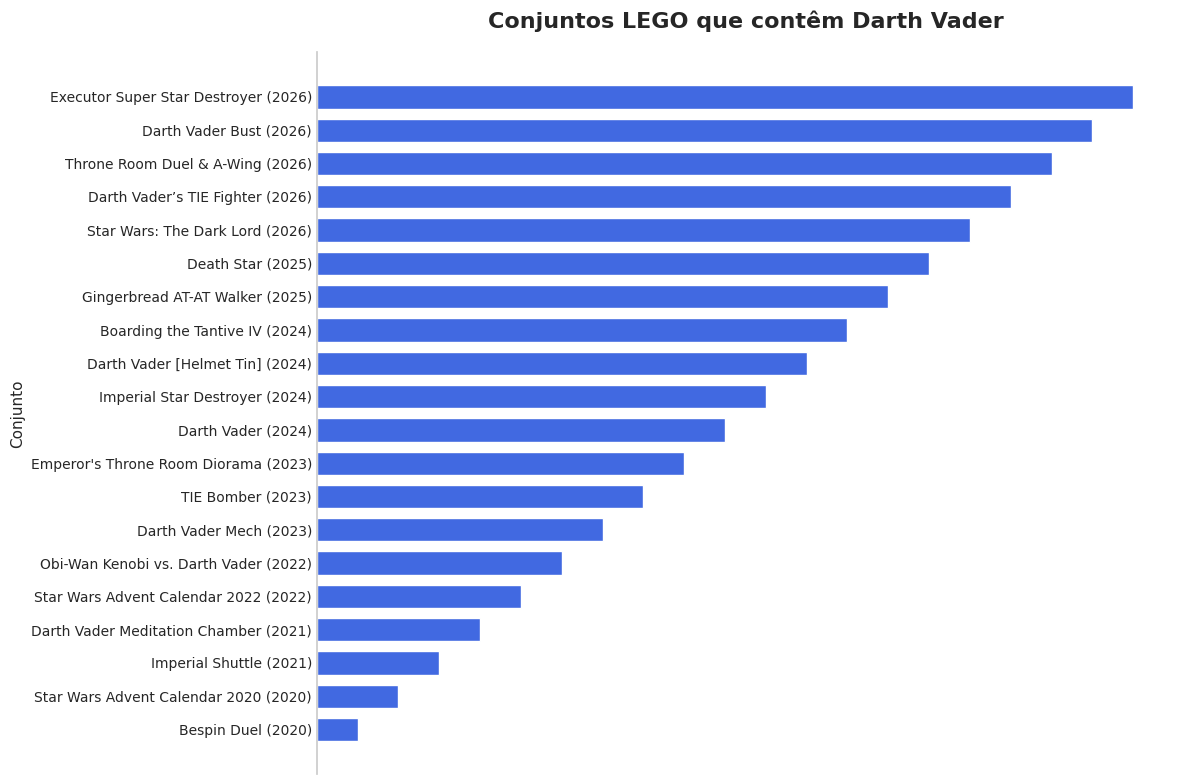

Total de conjuntos encontrados: 60
O gráfico apresenta até 20 conjuntos.


In [57]:

import matplotlib.pyplot as plt

# Converter o resultado da consulta para Pandas
df_vader = resultado_set_com_darth_vader.toPandas()

# Remover conjuntos duplicados
df_vader = (
    df_vader[["set_num", "set_name", "year"]]
    .drop_duplicates(subset="set_num")
    .sort_values("year", ascending=True)
)

# Selecionar os 20 conjuntos mais recentes
df_grafico = df_vader.tail(20).copy()

# Criar os rótulos com nome e ano
df_grafico["rotulo"] = (
    df_grafico["set_name"]
    + " ("
    + df_grafico["year"].astype(str)
    + ")"
)

# Inverter a ordem para deixar os mais recentes no topo
df_grafico = df_grafico.sort_values("year", ascending=False)

fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(
    df_grafico["rotulo"].iloc[::-1],
    range(1, len(df_grafico) + 1),
    color="#4169E1",
    height=0.7
)

ax.set_title(
    "Conjuntos LEGO que contêm Darth Vader",
    fontsize=16,
    fontweight="bold",
    pad=18
)

# Retirar o eixo X, pois as barras são apenas uma lista visual
ax.set_xlabel("")
ax.set_ylabel("Conjunto", fontsize=11)
ax.set_xticks([])

# Limpar elementos desnecessários
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.grid(False)

ax.tick_params(axis="y", labelsize=10, length=0)

plt.tight_layout()
plt.show()

print(f"Total de conjuntos encontrados: {len(df_vader)}")
print("O gráfico apresenta até 20 conjuntos.")





### Análise dos resultados

A consulta identificou 60 conjuntos LEGO que contêm a minifigura Darth Vader na base de dados analisada. O gráfico apresenta uma seleção de até 20 conjuntos, organizados visualmente por nome e ano de lançamento.

Os resultados mostram que a minifigura aparece em conjuntos de diferentes períodos, incluindo produtos lançados em 2000 e outros registrados em anos mais recentes, como 2026. Isso demonstra sua presença recorrente no catálogo analisado.

É importante destacar que a quantidade de conjuntos identificados não representa o número de unidades vendidas nem mede a popularidade comercial desses produtos.

### Conclusão

A análise identificou 60 conjuntos LEGO associados à minifigura Darth Vader. A consulta demonstra como o Spark SQL permite cruzar diferentes tabelas relacionais para localizar produtos que contêm uma minifigura específica. O resultado se limita aos registros disponíveis na base consultada.

## 3. Quais são os maiores conjuntos LEGO em quantidade de peças?

### Conceito

A quantidade de peças é uma característica que permite comparar o tamanho e a complexidade dos conjuntos LEGO. Esta análise busca identificar os conjuntos com maior número de peças registradas, permitindo observar quais produtos se destacam nesse aspecto.

### Explicação do código

Utilizamos o Spark SQL para consultar a tabela `sets`, selecionando o nome de cada conjunto e a coluna `num_parts`, que representa a quantidade de peças registrada para ele.

A consulta ordena os resultados de forma decrescente pela quantidade de peças, utilizando `ORDER BY num_parts DESC`, e limita a exibição aos dez primeiros registros com `LIMIT 10`.

Em seguida, o resultado é convertido para Pandas e representado em um gráfico de barras horizontais. O comprimento de cada barra corresponde à quantidade de peças do conjunto.

In [58]:
query_big_sets = """
SELECT
  sets.name,
  sets.num_parts
FROM sets
ORDER BY sets.num_parts DESC
LIMIT 10
"""

resultado_big_sets = spark.sql(query_big_sets)
resultado_big_sets.show()

+--------------------+---------+
|                name|num_parts|
+--------------------+---------+
|           World Map|    11695|
|        Eiffel Tower|    10001|
|The Ultimate Batt...|    10001|
|             Titanic|     9092|
|           Colosseum|     9036|
|          Death Star|     9031|
|The Lord of the R...|     8278|
|   Millennium Falcon|     7541|
|Venusaur, Chariza...|     6838|
|               AT-AT|     6785|
+--------------------+---------+



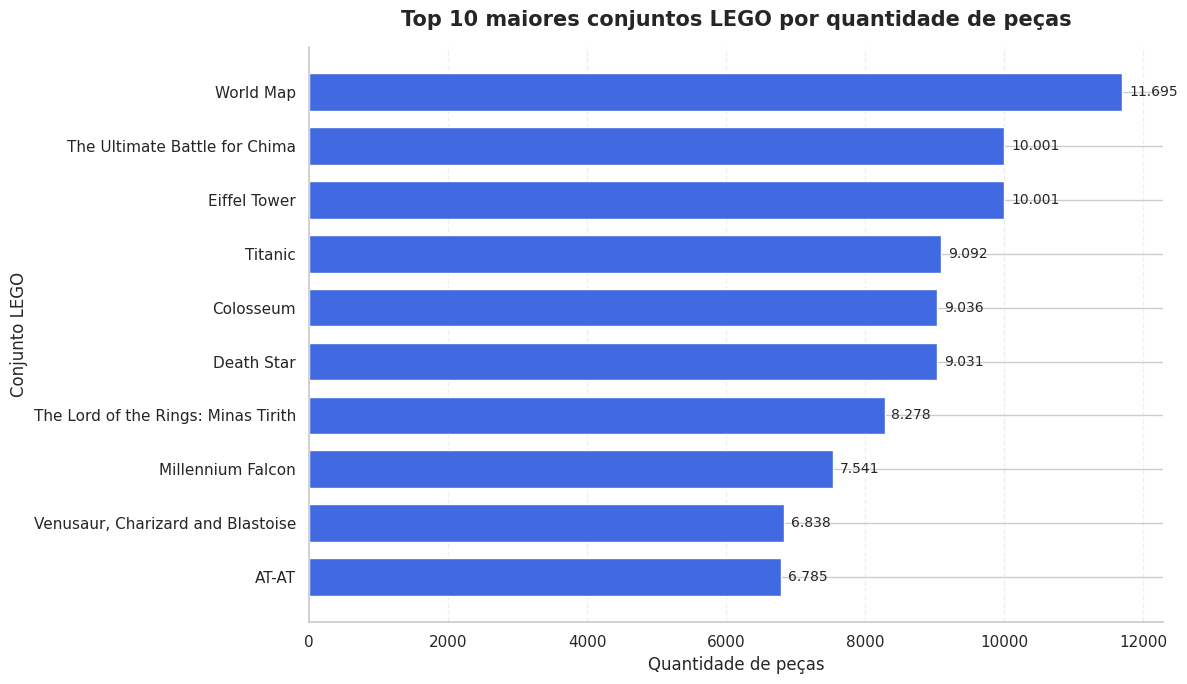

In [59]:

import matplotlib.pyplot as plt

# Converter o resultado do Spark para Pandas
df_grafico = resultado_big_sets.toPandas()

# Ordenar para deixar o maior conjunto no topo
df_grafico = df_grafico.sort_values(
    "num_parts", ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    df_grafico["name"],
    df_grafico["num_parts"],
    color="#4169E1",
    height=0.7
)

# Exibir a quantidade de peças ao final das barras
ax.bar_label(
    barras,
    labels=[
        f"{int(valor):,}".replace(",", ".")
        for valor in df_grafico["num_parts"]
    ],
    padding=5,
    fontsize=10
)

ax.set_title(
    "Top 10 maiores conjuntos LEGO por quantidade de peças",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Quantidade de peças")
ax.set_ylabel("Conjunto LEGO")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Análise dos resultados

O conjunto World Map aparece na primeira posição, com 11.695 peças registradas. Em seguida, aparecem Eiffel Tower e The Ultimate Battle for Chima, ambos com 10.001 peças.

Outros conjuntos que se destacam são Titanic, com 9.092 peças, e Colosseum, com 9.036 peças. Os resultados evidenciam diferenças expressivas na quantidade de peças entre os conjuntos selecionados.

A análise considera exclusivamente a quantidade de peças registrada na base de dados. Portanto, um conjunto com mais peças pode apresentar maior complexidade de montagem, mas essa característica não significa necessariamente que seja mais popular ou tenha maior sucesso comercial.

### Conclusão

A consulta identificou os dez conjuntos LEGO com maior quantidade de peças registrada. O World Map ocupa a primeira posição, seguido por Eiffel Tower e The Ultimate Battle for Chima. Esses resultados permitem comparar a dimensão dos maiores conjuntos presentes na base analisada, utilizando a quantidade de peças como critério.

## 4. Quais são os maiores conjuntos LEGO considerando seus temas?

### Conceito
Esta análise relaciona a quantidade de peças dos conjuntos LEGO aos seus respectivos temas. O objetivo é identificar os conjuntos que se destacam em tamanho e verificar a quais linhas temáticas pertencem.

### Explicação do código
Utilizamos o Spark SQL para relacionar as tabelas `sets` e `themes` por meio das colunas `theme_id` e `id`. O `LEFT JOIN` permite manter os conjuntos mesmo quando não há correspondência de tema.

Os resultados são ordenados pela quantidade de peças, em ordem decrescente, e limitados aos 15 maiores conjuntos. Em seguida, os dados são convertidos para Pandas e apresentados em um gráfico de barras horizontais, incluindo os nomes dos conjuntos e seus temas.

In [60]:
query_maiores_sets_temas = """
SELECT
  s.set_num,
  s.name AS set_name,
  s.year,
  s.num_parts,
  t.name AS theme_name
FROM sets s
LEFT JOIN themes t ON s.theme_id = t.id
ORDER BY s.num_parts DESC
LIMIT 15
"""

spark.sql(query_maiores_sets_temas).show(truncate=False)

+--------+-----------------------------------+----+---------+-------------------------+
|set_num |set_name                           |year|num_parts|theme_name               |
+--------+-----------------------------------+----+---------+-------------------------+
|31203-1 |World Map                          |2021|11695    |LEGO Art                 |
|10307-1 |Eiffel Tower                       |2022|10001    |Icons                    |
|BIGBOX-1|The Ultimate Battle for Chima      |2015|10001    |Legends of Chima         |
|10294-1 |Titanic                            |2021|9092     |Icons                    |
|10276-1 |Colosseum                          |2020|9036     |Icons                    |
|75419-1 |Death Star                         |2025|9031     |Ultimate Collector Series|
|11377-1 |The Lord of the Rings: Minas Tirith|2026|8278     |Icons                    |
|75192-1 |Millennium Falcon                  |2017|7541     |Ultimate Collector Series|
|72153-1 |Venusaur, Charizard an

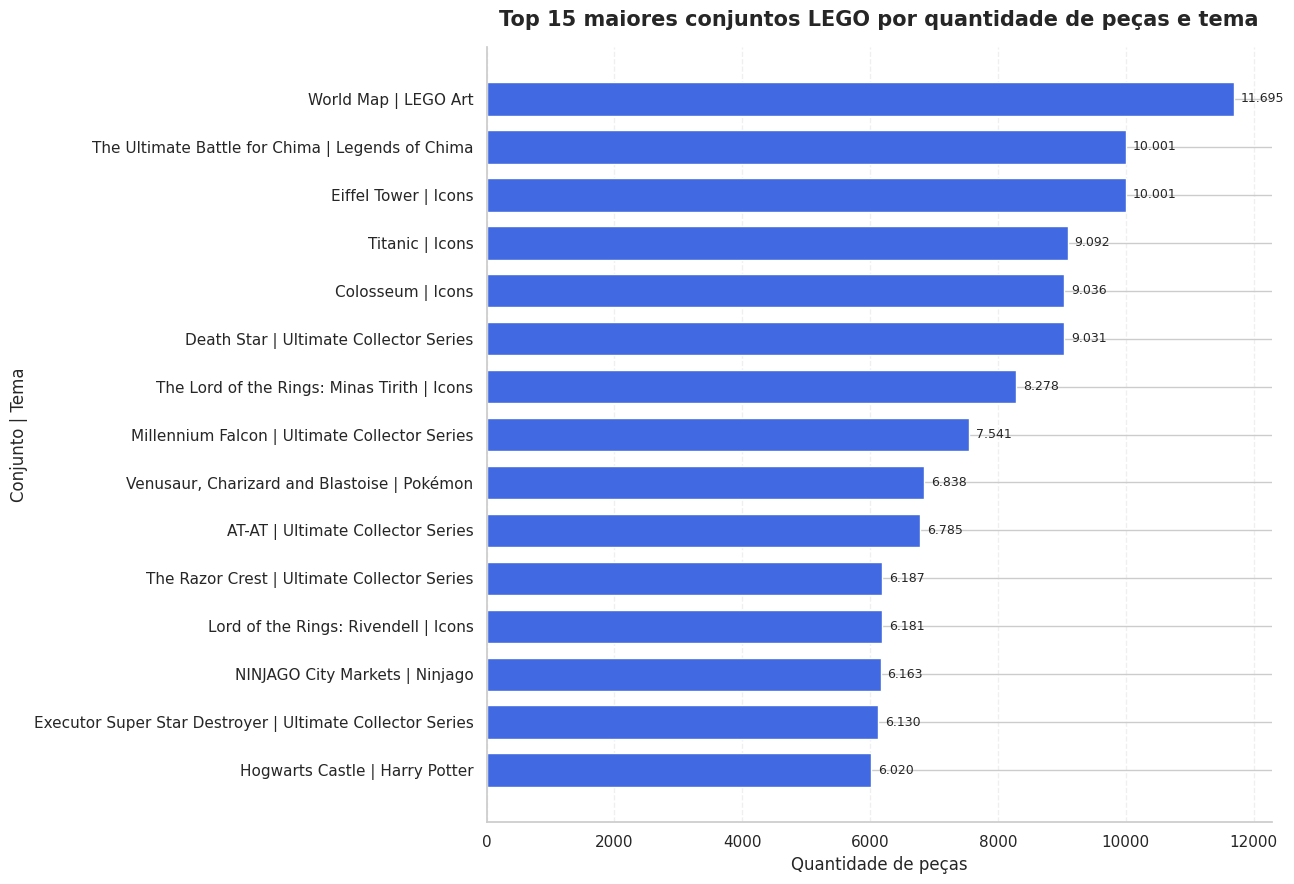

In [61]:

import matplotlib.pyplot as plt

# Converter o resultado Spark para Pandas
resultado_maiores_sets_temas = spark.sql(query_maiores_sets_temas)
df_grafico = resultado_maiores_sets_temas.toPandas()

# Preparar os rótulos com nome do conjunto e tema
df_grafico["rotulo"] = (
    df_grafico["set_name"]
    + " | "
    + df_grafico["theme_name"].fillna("Tema não informado")
)

# Ordenar para deixar o maior conjunto no topo
df_grafico = df_grafico.sort_values(
    "num_parts", ascending=True
)

fig, ax = plt.subplots(figsize=(13, 9))

barras = ax.barh(
    df_grafico["rotulo"],
    df_grafico["num_parts"],
    color="#4169E1",
    height=0.7
)

# Exibir quantidade de peças ao final das barras
ax.bar_label(
    barras,
    labels=[
        f"{int(valor):,}".replace(",", ".")
        for valor in df_grafico["num_parts"]
    ],
    padding=5,
    fontsize=9
)

ax.set_title(
    "Top 15 maiores conjuntos LEGO por quantidade de peças e tema",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Quantidade de peças")
ax.set_ylabel("Conjunto | Tema")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Análise dos resultados
O World Map, associado ao tema LEGO Art, ocupa a primeira posição, com 11.695 peças registradas. Em seguida, aparecem Eiffel Tower, do tema Icons, e The Ultimate Battle for Chima, de Legends of Chima, ambos com 10.001 peças.

Entre os 15 conjuntos apresentados, o tema Icons aparece em diferentes produtos, como Titanic e Colosseum. A linha Ultimate Collector Series também está presente em conjuntos como Death Star e Millennium Falcon.

Os resultados mostram que os maiores conjuntos estão distribuídos entre diferentes temas, embora algumas linhas apareçam repetidamente no ranking. Essa observação considera apenas os 15 conjuntos selecionados e não representa necessariamente a distribuição de tamanho de todos os conjuntos de cada tema.

### Conclusão
A análise permite identificar os maiores conjuntos LEGO e relacioná-los às suas linhas temáticas. Icons e Ultimate Collector Series aparecem em diversos conjuntos do ranking, enquanto o World Map, de LEGO Art, ocupa a primeira posição em quantidade de peças. Dessa forma, a consulta complementa a análise anterior ao acrescentar o contexto dos temas.

## 5. Quais conjuntos LEGO possuem mais minifiguras?

### Conceito
Esta análise busca identificar os conjuntos LEGO com maior quantidade de registros de minifiguras associados aos seus inventários. O objetivo é comparar os conjuntos e observar quais se destacam nesse aspecto.

### Explicação do código
Utilizamos o Spark SQL para relacionar as tabelas `sets`, `inventories` e `inventory_minifigs`. A função `COUNT()` contabiliza os registros de minifiguras associados a cada conjunto, enquanto o `GROUP BY` agrupa os resultados por conjunto.

O `LEFT JOIN` permite manter conjuntos mesmo quando não há registros correspondentes de minifiguras. Por fim, ordenamos os resultados em ordem decrescente e selecionamos os dez primeiros para apresentar em um gráfico de barras horizontais.

In [62]:
# Quais os sets com mais minifigs?
query_set_com_mais_minifigs = """
SELECT
  sets.set_num,
  sets.name AS set_name,
  COUNT(inventory_minifigs.fig_num) AS num_minifigs
  FROM sets
  LEFT JOIN inventories ON sets.set_num = inventories.set_num
  LEFT JOIN inventory_minifigs ON inventories.id = inventory_minifigs.inventory_id
  GROUP BY sets.set_num, sets.name
  ORDER BY num_minifigs DESC
  LIMIT 10
"""

resultado_set_com_mais_minifigs = spark.sql(query_set_com_mais_minifigs)
resultado_set_com_mais_minifigs.show(truncate=False)

+--------+----------------------------------+------------+
|set_num |set_name                          |num_minifigs|
+--------+----------------------------------+------------+
|BIGBOX-1|The Ultimate Battle for Chima     |69          |
|71741-1 |NINJAGO City Gardens              |66          |
|76178-1 |Daily Bugle                       |50          |
|3409-1  |Championship Challenge            |48          |
|9348-1  |Community Minifigures             |44          |
|9349-1  |Fairytale and Historic Minifigures|44          |
|10188-1 |Death Star                        |42          |
|75419-1 |Death Star                        |39          |
|75290-1 |Mos Eisley Cantina                |38          |
|9247-1  |Community Workers                 |31          |
+--------+----------------------------------+------------+



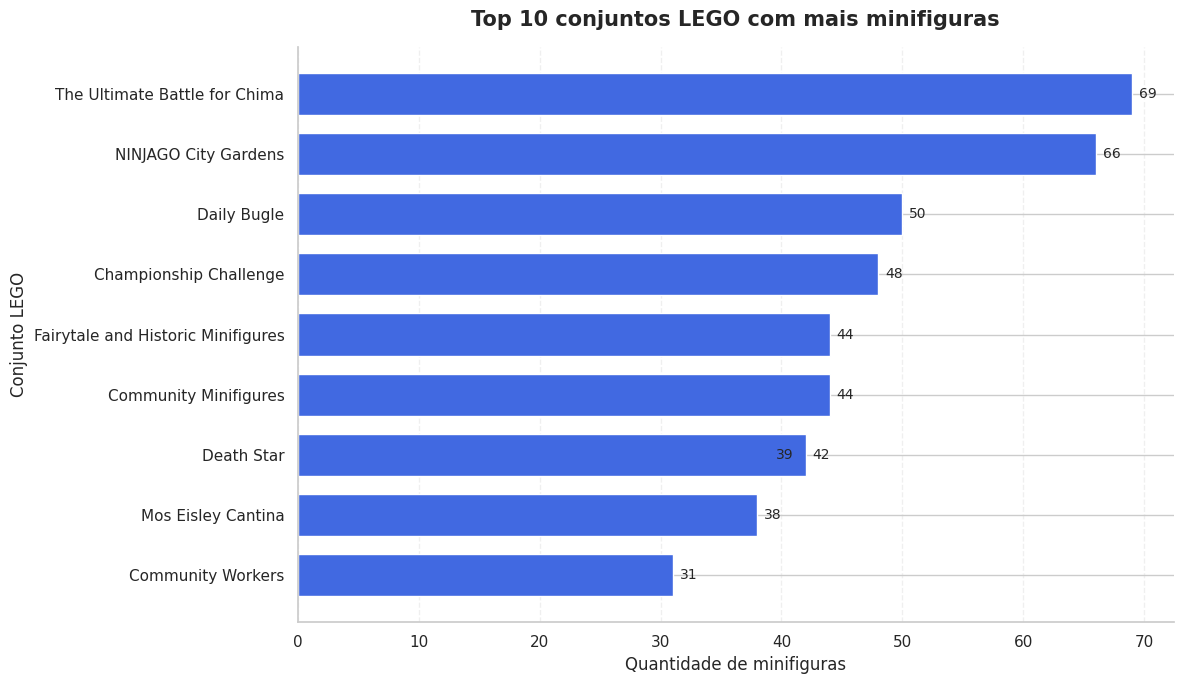

In [63]:

import matplotlib.pyplot as plt

# Converter o resultado do Spark para Pandas
df_grafico = resultado_set_com_mais_minifigs.toPandas()

# Ordenar para deixar o maior valor no topo
df_grafico = df_grafico.sort_values(
    "num_minifigs", ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    df_grafico["set_name"],
    df_grafico["num_minifigs"],
    color="#4169E1",
    height=0.7
)

# Mostrar os valores ao final das barras
ax.bar_label(
    barras,
    labels=[
        f"{int(valor):,}".replace(",", ".")
        for valor in df_grafico["num_minifigs"]
    ],
    padding=5,
    fontsize=10
)

ax.set_title(
    "Top 10 conjuntos LEGO com mais minifiguras",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Quantidade de minifiguras")
ax.set_ylabel("Conjunto LEGO")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Análise dos resultados
O conjunto BIGBOX-1 — The Ultimate Battle for Chima aparece na primeira posição, com 69 registros de minifiguras associados. Em seguida, aparece NINJAGO City Gardens, com 66, seguido por Daily Bugle, com 50.

Os resultados mostram diferenças na quantidade de registros de minifiguras entre os conjuntos apresentados. Entretanto, como a consulta considera os registros associados aos inventários, diferentes versões de inventário de um mesmo conjunto podem influenciar a contagem. Portanto, os valores devem ser interpretados como contagens obtidas a partir da estrutura dos dados, e não necessariamente como quantidades físicas exatas de minifiguras em cada produto.

### Conclusão
A consulta identificou os dez conjuntos com maiores contagens de registros de minifiguras associados aos seus inventários. O BIGBOX-1 ocupa a primeira posição, seguido por NINJAGO City Gardens e Daily Bugle. Essa análise demonstra como o Spark SQL permite combinar tabelas relacionais e agregar informações para comparar os conjuntos LEGO.

## 6. Existem outros conjuntos identificados como BIGBOX?

### Conceito
Esta análise busca verificar se existem conjuntos identificados como `BIGBOX` na base de dados do Rebrickable, identificando seus nomes e características registradas.

### Explicação do código
Utilizamos o Spark SQL para filtrar a tabela `sets` com base no identificador dos conjuntos. A condição `LIKE '%BIG%'` permite localizar identificadores que contêm a expressão `BIG`, facilitando a identificação desses registros.

In [64]:
# Existem outros BIGBOX?
query_for_big_box = """
SELECT
  sets.set_num,
  sets.name
FROM sets
WHERE sets.set_num LIKE '%BIG%'
"""

spark.sql(query_for_big_box).show(truncate=False)

+--------+-----------------------------+
|set_num |name                         |
+--------+-----------------------------+
|BIGBOX-1|The Ultimate Battle for Chima|
+--------+-----------------------------+



### Análise dos resultados
A consulta identificou um conjunto com o identificador `BIGBOX-1`, denominado *The Ultimate Battle for Chima*.

Não foram encontrados outros identificadores contendo a expressão `BIG` no resultado da consulta. Portanto, na base analisada, esse foi o único registro localizado pelo filtro utilizado.

### Conclusão
A consulta identificou apenas um conjunto com `BIG` em seu identificador: `BIGBOX-1 — The Ultimate Battle for Chima`. O resultado demonstra como filtros textuais no Spark SQL podem ser utilizados para localizar registros específicos em uma base de dados.

## 7. Quais materiais aparecem em maior quantidade nas peças LEGO?

### Conceito
Esta análise identifica os materiais com maior quantidade registrada nos inventários LEGO, permitindo comparar a presença de diferentes materiais na composição das peças.

### Explicação do código
Utilizamos o Spark SQL para relacionar as tabelas `parts` e `inventory_parts` por meio da coluna `part_num`. A função `SUM()` soma as quantidades registradas para cada material, e o `GROUP BY` agrupa os resultados por tipo de material.

Os resultados são ordenados em ordem decrescente de quantidade e apresentados em um gráfico de barras horizontais. A escala logarítmica facilita a visualização das diferenças entre materiais com quantidades muito distintas.

In [65]:
query_materiais = """
SELECT
    p.part_material,
    SUM(ip.quantity) AS quantidade_pecas
FROM parts p
JOIN inventory_parts ip
    ON p.part_num = ip.part_num
GROUP BY p.part_material
ORDER BY quantidade_pecas DESC
"""

resultado_materiais = spark.sql(query_materiais)

resultado_materiais.show(truncate=False)


+----------------+----------------+
|part_material   |quantidade_pecas|
+----------------+----------------+
|Plastic         |5247119         |
|Rubber          |39593           |
|Cardboard/Paper |4204            |
|Cloth           |3027            |
|Flexible Plastic|803             |
|Metal           |403             |
|Foam            |271             |
+----------------+----------------+



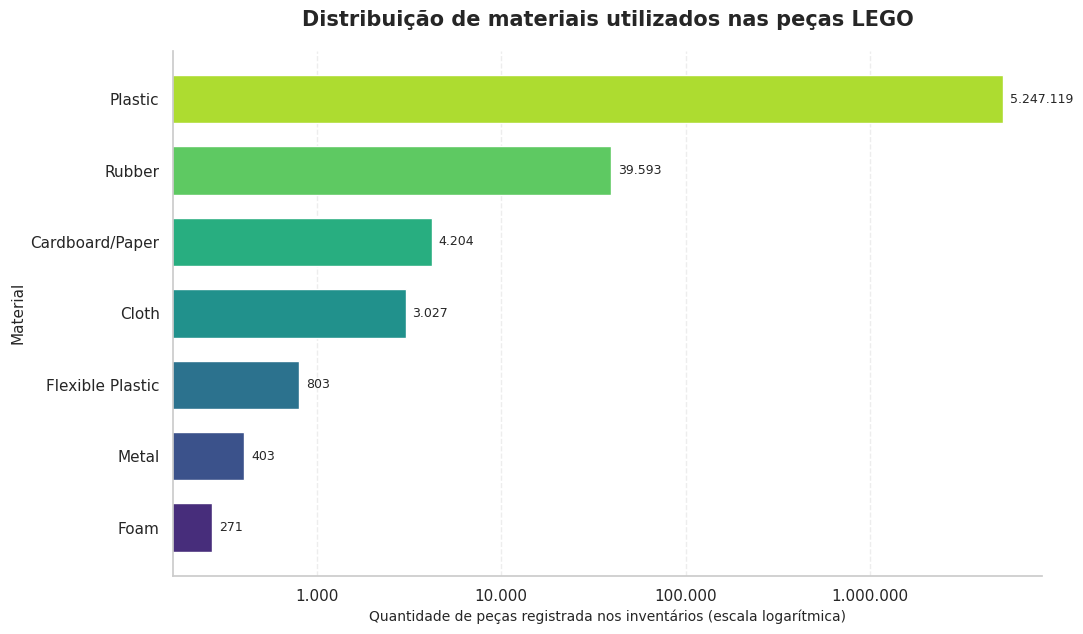

In [66]:

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Converter o resultado do Spark para Pandas
df_materiais = resultado_materiais.toPandas()

# Remover registros sem material informado
df_materiais = df_materiais.dropna(subset=["part_material"])

# Ordenar para deixar o material mais frequente no topo
df_materiais = df_materiais.sort_values(
    "quantidade_pecas", ascending=True
)

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6.5))

barras = ax.barh(
    df_materiais["part_material"],
    df_materiais["quantidade_pecas"],
    color=sns.color_palette("viridis", n_colors=len(df_materiais)),
    height=0.68
)

# Formatar os valores com separador de milhar
ax.bar_label(
    barras,
    labels=[
        f"{int(valor):,}".replace(",", ".")
        for valor in df_materiais["quantidade_pecas"]
    ],
    padding=5,
    fontsize=9
)

# Escala logarítmica para facilitar a comparação
# entre materiais com quantidades muito diferentes
ax.set_xscale("log")

ax.set_title(
    "Distribuição de materiais utilizados nas peças LEGO",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Quantidade de peças registrada nos inventários (escala logarítmica)",
    fontsize=10
)
ax.set_ylabel("Material", fontsize=11)

ax.xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}".replace(",", "."))
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.35)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Análise dos resultados
O plástico apresenta a maior quantidade registrada, com 5.247.119 unidades. Em seguida, aparecem a borracha, com 39.593, e o papel e papelão, com 4.204 unidades.

Os demais materiais apresentam quantidades significativamente menores, incluindo tecido, plástico flexível, metal e espuma. A diferença entre os valores evidencia a predominância do plástico nos registros analisados.

É importante destacar que os números representam a soma das quantidades de peças registradas nos inventários, e não a quantidade de modelos distintos de peças fabricadas com cada material.

### Conclusão
A análise mostra que o plástico é o material predominante nos inventários LEGO analisados, seguido pela borracha e pelo papel e papelão. A agregação com Spark SQL permite comparar os materiais e identificar aqueles com maior presença na base de dados.

## 8. Quais cores aparecem em maior quantidade nos inventários que contêm minifiguras?

### Conceito
Esta análise busca identificar as cores com maiores quantidades de peças registradas nos inventários que contêm minifiguras. O objetivo é comparar a distribuição das cores e visualizar aquelas com maior presença nos dados analisados.

### Explicação do código
Utilizamos o Spark SQL para relacionar as tabelas `inventory_minifigs`, `inventory_parts` e `colors`. A função `SUM()` soma as quantidades de peças por cor, e os resultados são ordenados em ordem decrescente, selecionando as 15 cores com maiores valores.

Em seguida, utilizamos Pandas para preparar os dados e construir um gráfico de pizza com as oito primeiras cores e uma categoria que reúne as demais cores presentes no resultado selecionado.

In [67]:
query_color_minifigs = """
SELECT
    c.name AS cor_nome,
    SUM(ip.quantity) AS quantidade_total
FROM inventory_minifigs im
JOIN inventory_parts ip ON im.inventory_id = ip.inventory_id
JOIN colors c ON ip.color_id = c.id
GROUP BY c.name
ORDER BY quantidade_total DESC
LIMIT 15
"""

resultado_color_minifigs = spark.sql(query_color_minifigs)
resultado_color_minifigs.show(truncate=False)

+-----------------+----------------+
|cor_nome         |quantidade_total|
+-----------------+----------------+
|Black            |2832304         |
|Light Bluish Gray|2611264         |
|Dark Bluish Gray |1891126         |
|White            |1668934         |
|Reddish Brown    |1034909         |
|Tan              |824592          |
|Red              |786010          |
|Dark Tan         |425310          |
|Blue             |397466          |
|Yellow           |382453          |
|Pearl Gold       |310528          |
|Green            |242887          |
|Medium Nougat    |226632          |
|Dark Red         |216386          |
|Trans-Clear      |215534          |
+-----------------+----------------+



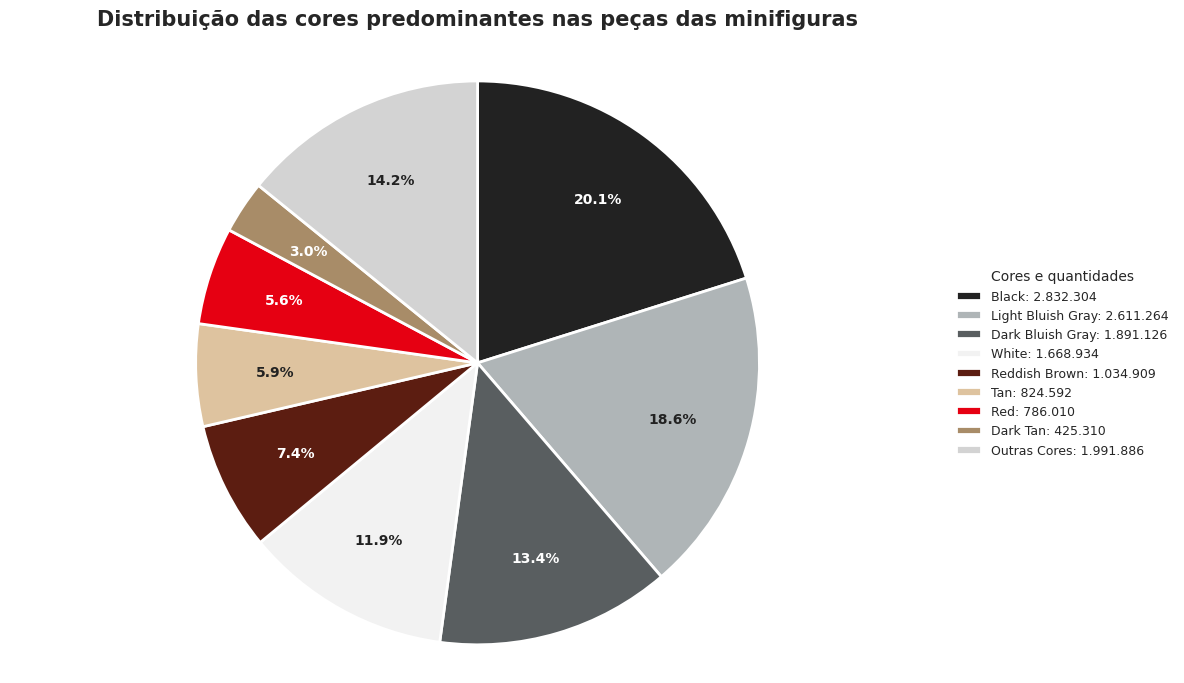

In [68]:

# Preparar os dados para o gráfico de pizza

import pandas as pd

df_colors = resultado_color_minifigs.toPandas()

# Selecionar as 8 cores mais frequentes
top_n = 8
df_top_colors = df_colors.head(top_n).copy()

# Agrupar as demais cores
outras_total = df_colors.iloc[top_n:]["quantidade_total"].sum()

if outras_total > 0:
    df_top_colors = pd.concat([
        df_top_colors,
        pd.DataFrame([{
            "cor_nome": "Outras Cores",
            "quantidade_total": outras_total
        }])
    ], ignore_index=True)

import matplotlib.pyplot as plt
import pandas as pd

# Paleta com cores próximas às cores reais das peças
color_map = {
    "Black": "#222222",
    "White": "#F2F2F2",
    "Red": "#E60012",
    "Yellow": "#F2CD37",
    "Blue": "#0055A4",
    "Dark Bluish Gray": "#595E60",
    "Light Bluish Gray": "#AFB5B7",
    "Reddish Brown": "#5C1D11",
    "Tan": "#DEC39F",
    "Dark Tan": "#A88C68",
    "Green": "#008542",
    "Orange": "#F57D11",
    "Lime": "#BBE90B",
    "Pink": "#FEA6C3",
    "Outras Cores": "#D3D3D3"
}

# Preparar dados e cores
labels = df_top_colors["cor_nome"]
valores = df_top_colors["quantidade_total"]

cores = [
    color_map.get(cor, "#9E9E9E")
    for cor in labels
]

# Criar gráfico
fig, ax = plt.subplots(figsize=(12, 7))

wedges, texts, autotexts = ax.pie(
    valores,
    labels=None,
    colors=cores,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.72,
    wedgeprops={
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 10
    }
)

# Melhorar a leitura das porcentagens
for texto in autotexts:
    texto.set_fontsize(10)
    texto.set_fontweight("bold")
    texto.set_color("white")

# Fatias claras precisam de texto escuro
cores_claras = {"White", "Tan", "Light Bluish Gray",
                "Yellow", "Lime", "Pink", "Outras Cores"}

for i, texto in enumerate(autotexts):
    if labels.iloc[i] in cores_claras:
        texto.set_color("#222222")

# Legenda organizada à direita
ax.legend(
    wedges,
    [
        f"{cor}: {valor:,.0f}".replace(",", ".")
        for cor, valor in zip(labels, valores)
    ],
    title="Cores e quantidades",
    loc="center left",
    bbox_to_anchor=(1, 0.5),
    frameon=False,
    fontsize=9,
    title_fontsize=10
)

ax.set_title(
    "Distribuição das cores predominantes nas peças das minifiguras",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.axis("equal")
plt.tight_layout()
plt.show()


### Análise dos resultados
A cor Black apresenta a maior quantidade registrada, com 2.832.304 unidades. Em seguida, aparecem Light Bluish Gray, com 2.611.264, Dark Bluish Gray, com 1.891.126, e White, com 1.668.934.

O gráfico de pizza facilita a comparação proporcional entre as categorias selecionadas, enquanto o gráfico de barras permite comparar as quantidades registradas. Os resultados evidenciam a presença expressiva de tons escuros e cinzentos entre as cores analisadas.

É importante destacar que a consulta contabiliza as peças dos inventários dos conjuntos que contêm minifiguras, e não exclusivamente as peças que compõem as próprias minifiguras. Além disso, a categoria "Outras Cores" do gráfico de pizza reúne as cores restantes entre as 15 selecionadas pela consulta.

### Conclusão
A análise identificou Black, Light Bluish Gray e Dark Bluish Gray como as três cores com maiores quantidades registradas nos inventários analisados. Os gráficos complementam a consulta SQL ao apresentar a distribuição das cores de maneira visual, respeitando os limites dos dados utilizados.

## 9. Quais são as cores mais frequentes nas cabeças das minifiguras LEGO?

### Conceito
Esta análise investiga a distribuição das cores das peças classificadas como cabeças de minifiguras LEGO, permitindo identificar quais cores aparecem em maior quantidade nos inventários analisados.

### Explicação do código
Utilizamos o Spark SQL para relacionar as tabelas `inventory_minifigs`, `inventory_parts`, `parts`, `part_categories` e `colors`. A condição `LIKE '%Minifig Heads%'` filtra as peças cuja categoria contém essa expressão.

A função `SUM()` soma as quantidades registradas por cor, e o `GROUP BY` agrupa os resultados. Por fim, selecionamos as 15 cores com maiores quantidades e utilizamos Pandas e Matplotlib para construir um gráfico de barras horizontais.

In [69]:
# Identificar a categoria correspondente a cabeças e buscar a distribuição de cores
query_cabecas_cores = """
SELECT
    c.name AS cor_nome,
    SUM(ip.quantity) AS quantidade_total
FROM inventory_minifigs im
JOIN inventory_parts ip ON im.inventory_id = ip.inventory_id
JOIN parts p ON ip.part_num = p.part_num
JOIN part_categories pc ON p.part_cat_id = pc.id
JOIN colors c ON ip.color_id = c.id
WHERE pc.name LIKE '%Minifig Heads%'
GROUP BY c.name
ORDER BY quantidade_total DESC
LIMIT 15
"""

df_cabecas = spark.sql(query_cabecas_cores)
df_cabecas.show(truncate=False)

+-----------------+----------------+
|cor_nome         |quantidade_total|
+-----------------+----------------+
|White            |2519            |
|Trans-Clear      |1482            |
|Trans-Red        |1020            |
|Trans-Light Blue |981             |
|Black            |927             |
|Yellow           |543             |
|Pearl Gold       |527             |
|Trans-Yellow     |449             |
|Trans-Neon Orange|420             |
|Medium Nougat    |395             |
|Orange           |340             |
|Red              |340             |
|Light Bluish Gray|312             |
|Trans-Neon Green |297             |
|Tan              |279             |
+-----------------+----------------+



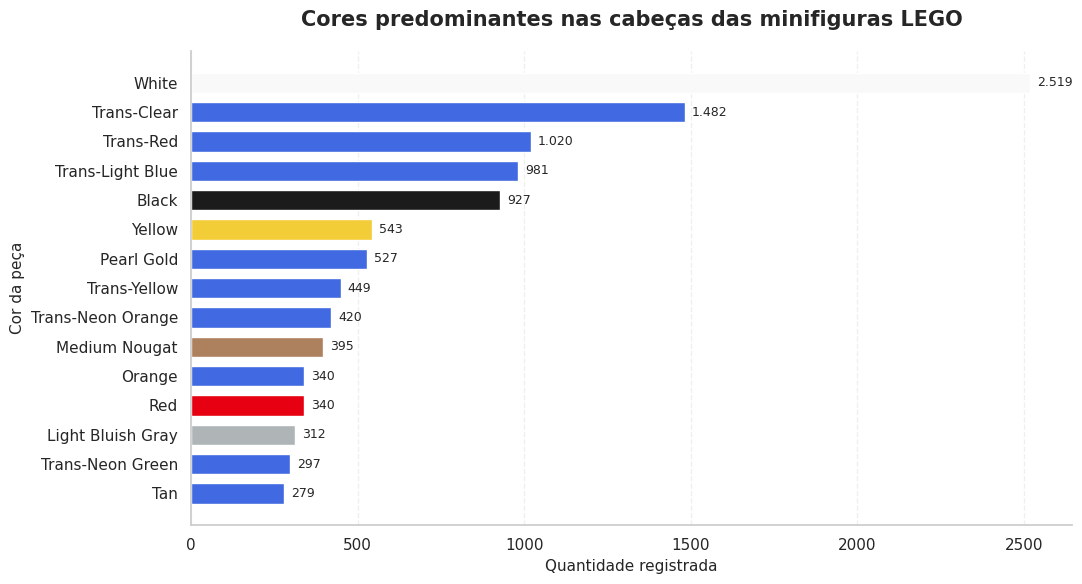

In [70]:

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# Mapa de cores aproximadas das peças LEGO
color_map_heads = {
    "Yellow": "#F2CD37",
    "White": "#F9F9F9",
    "Light Flesh": "#F6D5C8",
    "Flesh": "#D6A28C",
    "Dark Flesh": "#7C4F3B",
    "Medium Nougat": "#AD805E",
    "Black": "#1B1B1B",
    "Red": "#E60012",
    "Blue": "#0055A5",
    "Light Bluish Gray": "#AFB5B7",
    "Dark Bluish Gray": "#595E60"
}

# Converter o resultado do Spark para Pandas
df_cabecas_pandas = df_cabecas.toPandas()

# Ordenar do menor para o maior para deixar o maior no topo
df_grafico = df_cabecas_pandas.copy()
df_grafico = df_grafico.sort_values(
    "quantidade_total", ascending=True
)

# Aplicar as cores correspondentes
bar_colors = [
    color_map_heads.get(cor, "#4169E1")
    for cor in df_grafico["cor_nome"]
]

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    df_grafico["cor_nome"],
    df_grafico["quantidade_total"],
    color=bar_colors,
    height=0.7,
    edgecolor="white",
    linewidth=1
)

# Exibir os valores no final das barras
ax.bar_label(
    barras,
    labels=[
        f"{int(valor):,}".replace(",", ".")
        for valor in df_grafico["quantidade_total"]
    ],
    padding=5,
    fontsize=9
)

ax.set_title(
    "Cores predominantes nas cabeças das minifiguras LEGO",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Quantidade registrada", fontsize=11)
ax.set_ylabel("Cor da peça", fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Análise dos resultados
A cor White apresenta a maior quantidade registrada, com 2.519 unidades. Em seguida, aparecem Trans-Clear, com 1.482, e Trans-Red, com 1.020. Também se destacam Trans-Light Blue, com 981, e Black, com 927.

Os resultados mostram a presença de cores sólidas e transparentes entre as categorias com maiores quantidades registradas. O gráfico facilita a comparação entre as 15 cores selecionadas.

É importante destacar que os valores representam as quantidades registradas nos inventários associados às minifiguras, após o filtro pela categoria de cabeças, e não necessariamente o número de cabeças únicas produzidas em cada cor.

### Conclusão
A análise identificou White, Trans-Clear e Trans-Red como as três cores com maiores quantidades registradas entre as peças classificadas como cabeças de minifiguras. A consulta demonstra como o Spark SQL pode combinar tabelas relacionais e agregar dados para investigar características específicas dos componentes LEGO.

**GET — Verificação da qualidade dos dados**

Nesta etapa, verificamos a presença de valores nulos e registros duplicados nas tabelas utilizadas no projeto, buscando identificar possíveis problemas que possam afetar as análises.

In [71]:
# Verificação inicial da qualidade dos dados

tabelas_auditoria = [
    "sets",
    "themes",
    "parts",
    "inventories",
    "inventory_parts",
    "minifigs",
    "inventory_minifigs",
    "colors"
]

for nome in tabelas_auditoria:
    df = dataframes[nome]

    total_linhas = len(df)

    print(f"\n{'=' * 45}")
    print(f"Tabela: {nome}")
    print(f"Total de linhas: {total_linhas:,}")

    # Verificar valores nulos por coluna
    nulos = df.isnull().sum()
    nulos = nulos[nulos > 0]

    if nulos.empty:
        print("Valores nulos: nenhum")
    else:
        print("Valores nulos por coluna:")
        print(nulos.to_string())

    # Verificar linhas totalmente duplicadas
    duplicadas = df.duplicated().sum()
    print(f"Linhas totalmente duplicadas: {duplicadas:,}")



Tabela: sets
Total de linhas: 28,544
Valores nulos: nenhum
Linhas totalmente duplicadas: 0

Tabela: themes
Total de linhas: 496
Valores nulos por coluna:
parent_id    150
Linhas totalmente duplicadas: 0

Tabela: parts
Total de linhas: 64,897
Valores nulos: nenhum
Linhas totalmente duplicadas: 0

Tabela: inventories
Total de linhas: 47,789
Valores nulos: nenhum
Linhas totalmente duplicadas: 0

Tabela: inventory_parts
Total de linhas: 1,567,180
Valores nulos por coluna:
img_url    7133
Linhas totalmente duplicadas: 0

Tabela: minifigs
Total de linhas: 17,293
Valores nulos: nenhum
Linhas totalmente duplicadas: 0

Tabela: inventory_minifigs
Total de linhas: 25,903
Valores nulos: nenhum
Linhas totalmente duplicadas: 0

Tabela: colors
Total de linhas: 275
Valores nulos por coluna:
y1    2
y2    2
Linhas totalmente duplicadas: 0


### Análise da qualidade dos dados

A verificação inicial de qualidade foi realizada em oito tabelas do conjunto de dados LEGO, analisando valores nulos e registros totalmente duplicados.

Nenhuma das tabelas analisadas apresentou linhas totalmente duplicadas. Também não foram identificados valores nulos nas tabelas `sets`, `parts`, `inventories`, `minifigs` e `inventory_minifigs`.

Na tabela `themes`, foram encontrados 150 valores nulos na coluna `parent_id`. Esses valores podem indicar temas que não possuem um tema superior associado, hipótese que deve ser considerada antes de qualquer tratamento.

Na tabela `inventory_parts`, foram identificados 7.133 valores nulos em `img_url`. Como essa coluna está relacionada à URL de imagens, sua ausência não implica necessariamente um problema para as análises quantitativas das peças.

Por fim, a tabela `colors` apresentou dois valores nulos em cada uma das colunas `y1` e `y2`. É necessário compreender a finalidade dessas colunas para determinar se os valores ausentes afetam as análises.

**Conclusão:** a verificação inicial não identificou duplicatas completas nas tabelas analisadas. Os valores nulos encontrados serão avaliados conforme sua finalidade e seu impacto nas consultas, evitando a exclusão desnecessária de registros válidos.

### Validação de chaves e relacionamentos

Nesta etapa, verificamos a unicidade dos identificadores das principais tabelas e a integridade dos relacionamentos entre elas. Essa análise complementa a verificação de valores nulos e duplicatas, ajudando a identificar possíveis inconsistências que possam afetar as consultas SQL.

In [72]:

# Verificação de chaves principais

chaves_principais = {
    "sets": "set_num",
    "themes": "id",
    "parts": "part_num",
    "inventories": "id",
    "minifigs": "fig_num",
    "colors": "id"
}

for tabela, coluna in chaves_principais.items():
    df = dataframes[tabela]

    valores_nulos = df[coluna].isnull().sum()
    valores_duplicados = df[coluna].duplicated().sum()

    print(f"\nTabela: {tabela}")
    print(f"Coluna identificadora: {coluna}")
    print(f"Valores nulos: {valores_nulos:,}")
    print(f"Valores duplicados: {valores_duplicados:,}")



Tabela: sets
Coluna identificadora: set_num
Valores nulos: 0
Valores duplicados: 0

Tabela: themes
Coluna identificadora: id
Valores nulos: 0
Valores duplicados: 0

Tabela: parts
Coluna identificadora: part_num
Valores nulos: 0
Valores duplicados: 0

Tabela: inventories
Coluna identificadora: id
Valores nulos: 0
Valores duplicados: 0

Tabela: minifigs
Coluna identificadora: fig_num
Valores nulos: 0
Valores duplicados: 0

Tabela: colors
Coluna identificadora: id
Valores nulos: 0
Valores duplicados: 0


### Conclusão da verificação das chaves principais

A verificação das colunas identificadoras das tabelas `sets`, `themes`, `parts`, `inventories`, `minifigs` e `colors` não identificou valores nulos nem valores duplicados nas respectivas chaves analisadas.

Esses resultados indicam que as colunas verificadas apresentam consistência quanto à ausência de valores nulos e duplicações, contribuindo para a confiabilidade dos relacionamentos entre as tabelas.

Entretanto, essa verificação não garante, isoladamente, a integridade de todos os relacionamentos ou a ausência de outros problemas de qualidade nos dados.

# MODEL — Construção e avaliação do modelo de Machine Learning

Nesta etapa, utilizamos o Spark MLlib para investigar se características dos conjuntos LEGO ajudam a estimar a recorrência dos produtos no catálogo.

Como a base de dados não contém informações diretas de vendas ou receita, definimos como variável-alvo a quantidade de anos distintos em que cada produto aparece durante uma janela de observação de oito anos. Essa medida é utilizada como uma aproximação da permanência do produto no catálogo, não como uma medida direta de sucesso comercial.

O desempenho dos modelos é comparado com um baseline e avaliado por métricas de erro e capacidade de distinguir produtos que reaparecem daqueles que não reaparecem.

Prevendo o "sucesso" de um set LEGO com Machine Learning
Pergunta: é possível prever o "sucesso" de um novo set a partir das suas características?

Como medimos "sucesso": pela quantidade de anos em que o produto aparece no catálogo (uma proxy: quanto mais anos, mais o produto "se sustentou").

Abordagem: aprendizado supervisionado de regressão (LinearRegression e DecisionTreeRegressor do pyspark.ml), com features construídas por Spark SQL.

2.1 Definindo a variável-alvo
No Rebrickable, sets.year é o ano de lançamento do set, e cada set_num tem um único ano.

Um mesmo produto é lançado de novo em anos diferentes com set_num diferentes (ex.: Millennium Falcon, Police Station). Então, para calcular a recorrência usamos:

Produto = par (nome normalizado, theme_id). O nome é normalizado com LOWER(TRIM(...)) junto com o tema para evitar juntar produtos de linhas diferentes que têm o mesmo nome.
anos_no_catalogo = número de anos distintos em que o produto aparece. Usamos anos distintos porque muitos produtos reaparecem, somem e voltam.
Um detalhe:
um set lançado em 2024 ainda não teve tempo de reaparecer. Se contássemos todos os anos até hoje, o modelo aprenderia "lançamento recente = fracasso", então vamos olhar só os primeiros anos de cada produto e incluir apenas produtos que já completaram uma janela.

In [73]:
# ---------------------------------------------------------------------------------
# Parâmetros da análise (centralizados aqui para facilitar testes de sensibilidade)
# ---------------------------------------------------------------------------------
import pandas as pd
import numpy as np
from pyspark.sql import functions as F

JANELA_ANOS         = 8     # observamos cada produto nos primeiros 8 anos a partir do lançamento
ULTIMO_ANO_COMPLETO = 2025  # 2026 ainda está em andamento (novos sets entram na base), então não conta
ANO_CORTE_TREINO    = 2013  # treino: lançados até 2013 | teste: lançados de 2014 em diante
TOP_N_TEMAS         = 25    # temas raiz mais frequentes no treino; os demais viram "Outros"
SEMENTE             = 42    # reprodutibilidade

# Último ano de lançamento que já completou a janela de observação:
# com janela de 8 anos, um produto lançado em 2018 é observado de 2018 a 2025.
ULTIMO_LANCAMENTO_ELEGIVEL = ULTIMO_ANO_COMPLETO - JANELA_ANOS + 1
print(f"Coorte elegível: produtos lançados até {ULTIMO_LANCAMENTO_ELEGIVEL}")

# Número de partições
spark.conf.set("spark.sql.shuffle.partitions", "8")

Coorte elegível: produtos lançados até 2018


Construindo o alvo com Spark SQL
Primeiro uma view com o nome normalizado, depois uma view produtos que agrega os anos de cada produto. O COUNT(DISTINCT CASE WHEN ...) conta apenas os anos que caem dentro da janela de observação do produto.

In [74]:
# View base: cada set com seu nome normalizado
spark.sql('''
    CREATE OR REPLACE TEMP VIEW sets_norm AS
    SELECT set_num, year, theme_id, num_parts, LOWER(TRIM(name)) AS nome_norm
    FROM sets
''')

# View `produtos`: uma linha por (nome normalizado, tema) com o alvo
spark.sql(f'''
    CREATE OR REPLACE TEMP VIEW produtos AS
    SELECT
        s.nome_norm,
        s.theme_id,
        MIN(s.year)                       AS ano_lancamento,
        COUNT(DISTINCT s.year)            AS anos_total,          -- total histórico (só descritivo; NÃO é o alvo)
        COUNT(DISTINCT CASE WHEN s.year <= p.ano_lancamento + {JANELA_ANOS} - 1
                            THEN s.year END) AS anos_no_catalogo  -- ALVO: anos distintos dentro da janela
    FROM sets_norm s
    JOIN (SELECT nome_norm, theme_id, MIN(year) AS ano_lancamento
          FROM sets_norm GROUP BY nome_norm, theme_id) p
      ON s.nome_norm = p.nome_norm AND s.theme_id = p.theme_id
    GROUP BY s.nome_norm, s.theme_id, p.ano_lancamento
''')

spark.sql("SELECT COUNT(*) AS n_produtos FROM produtos").show()
spark.sql("SELECT * FROM produtos WHERE nome_norm = 'millennium falcon' ORDER BY theme_id").show(truncate=False)

+----------+
|n_produtos|
+----------+
|     25955|
+----------+

+-----------------+--------+--------------+----------+----------------+
|nome_norm        |theme_id|ano_lancamento|anos_total|anos_no_catalogo|
+-----------------+--------+--------------+----------+----------------+
|millennium falcon|158     |2000          |11        |2               |
|millennium falcon|171     |2007          |2         |1               |
+-----------------+--------+--------------+----------+----------------+



Validação cruzada com RDD
Para garantir que o alvo está certo, construímos a mesma variável por outro caminho, usando a API de RDD (map + reduceByKey), e comparamos com o resultado do SQL. Se as duas implementações divergirem, algo está errado em uma delas.

A ideia: cada set vira ((nome, tema), {ano}); o reduceByKey une os conjuntos de anos de cada produto; por fim contamos os anos dentro da janela.

In [75]:
# Validar o alvo anos_no_catalogo usando RDD

rdd_alvo = (
    spark.table("sets_norm")
    .select("nome_norm", "theme_id", "year")
    .rdd
    .map(lambda row: (
        (row["nome_norm"], row["theme_id"]),
        row["year"]
    ))
    .filter(lambda item: item[1] is not None)
    .mapValues(lambda ano: {ano})
    .reduceByKey(lambda anos_a, anos_b: anos_a | anos_b)
    .mapValues(
        lambda anos: len({
            ano for ano in anos
            if ano <= min(anos) + JANELA_ANOS - 1
        })
    )
)

df_rdd_alvo = spark.createDataFrame(
    rdd_alvo.map(lambda item: (
        item[0][0],
        item[0][1],
        item[1]
    )),
    ["nome_norm", "theme_id", "anos_no_catalogo_rdd"]
)

df_sql_alvo = spark.table("produtos").select(
    "nome_norm", "theme_id", "anos_no_catalogo"
)

comparacao = (
    df_sql_alvo
    .join(df_rdd_alvo, ["nome_norm", "theme_id"], "full")
)

divergencias = comparacao.filter(
    comparacao.anos_no_catalogo.isNull()
    | comparacao.anos_no_catalogo_rdd.isNull()
    | (
        comparacao.anos_no_catalogo
        != comparacao.anos_no_catalogo_rdd
    )
)

print("Total de produtos no SQL:", df_sql_alvo.count())
print("Total de produtos no RDD:", df_rdd_alvo.count())
print("Total de divergências:", divergencias.count())

divergencias.show(10, truncate=False)

Total de produtos no SQL: 25955
Total de produtos no RDD: 25955
Total de divergências: 0
+---------+--------+----------------+--------------------+
|nome_norm|theme_id|anos_no_catalogo|anos_no_catalogo_rdd|
+---------+--------+----------------+--------------------+
+---------+--------+----------------+--------------------+



### Análise e conclusão da validação com RDD

A validação comparou a variável-alvo `anos_no_catalogo`, calculada por Spark SQL, com uma implementação independente utilizando RDDs e as operações `map` e `reduceByKey`.

As duas abordagens retornaram 25.955 produtos, sem divergências entre os valores calculados. Esse resultado confirma a consistência entre as implementações para a regra de cálculo utilizada.

A validação também demonstra a aplicação de transformações distribuídas com RDDs, complementando o processamento realizado com Spark SQL. Embora essa concordância não garanta a ausência de todos os possíveis problemas nos dados, ela aumenta a confiança na construção da variável-alvo.

## 2.2 Engenharia de features

Usamos as informações de features **disponíveis no lançamento**, não em todos os anos que o set aparece. Isso evitaria **vazamento de dados**.

**Características selecionadas para o modelo:**

| Feature | Origem (tabelas) | Intuição |
|---|---|---|
| `ano_lancamento` | `sets` | Representa o efeito da época de lançamento. |
| `log_num_parts` | `sets` | Representa o tamanho e a complexidade do conjunto; a transformação logarítmica reduz a assimetria da distribuição. |
| `sem_pecas` | `sets` | Indica conjuntos com `num_parts = 0`, como livros e itens promocionais. |
| `n_variantes_lancamento` | `sets` | Quantidade de conjuntos associados ao mesmo produto no ano de lançamento. |
| `nome_n_palavras` | `sets` | Representa o comprimento do nome do produto, que pode capturar diferenças de nomenclatura. |
| `tema_raiz` | `themes` | Representa a linha de produto, como Star Wars, City ou Technic. |

**Critério de seleção:** mantivemos características disponíveis no lançamento ou derivadas de informações desse período. As variáveis de inventário (`num_minifigs`, `pecas_distintas`, `num_cores` e `n_sets_contidos`) foram retiradas do conjunto de entrada dos modelos para reduzir o risco de vazamento temporal, pois são calculadas a partir de inventários que podem refletir informações posteriores ao lançamento.

In [76]:
# 1) Apenas a versão mais recente do inventário de cada set
spark.sql('''
    CREATE OR REPLACE TEMP VIEW inv_atual AS
    SELECT i.id AS inventory_id, i.set_num
    FROM inventories i
    JOIN (SELECT set_num, MAX(version) AS v FROM inventories GROUP BY set_num) m
      ON i.set_num = m.set_num AND i.version = m.v
''')

# 2) Tema raiz: sobe até 2 níveis na hierarquia (profundidade máxima observada = 2)
spark.sql('''
    CREATE OR REPLACE TEMP VIEW temas_raiz AS
    SELECT t0.id AS theme_id,
           COALESCE(t2.name, t1.name, t0.name) AS tema_raiz   -- o ancestral mais alto que existir
    FROM themes t0
    LEFT JOIN themes t1 ON t0.parent_id = t1.id
    LEFT JOIN themes t2 ON t1.parent_id = t2.id
''')

# 3) Features no nível do SET (cada subquery agrega uma tabela de ligação por inventory_id)
spark.sql('''
    CREATE OR REPLACE TEMP VIEW feats_set AS
    SELECT
        s.set_num, s.nome_norm, s.theme_id, s.year, s.num_parts,
        COALESCE(mf.num_minifigs, 0)     AS num_minifigs,
        COALESCE(pp.pecas_distintas, 0)  AS pecas_distintas,
        COALESCE(pp.num_cores, 0)        AS num_cores,
        COALESCE(isets.n_sets_contidos, 0) AS n_sets_contidos
    FROM sets_norm s
    LEFT JOIN inv_atual ia ON ia.set_num = s.set_num
    LEFT JOIN (SELECT inventory_id, SUM(quantity) AS num_minifigs
               FROM inventory_minifigs GROUP BY inventory_id) mf
           ON mf.inventory_id = ia.inventory_id
    LEFT JOIN (SELECT inventory_id,
                      COUNT(DISTINCT part_num) AS pecas_distintas,
                      COUNT(DISTINCT color_id) AS num_cores
               FROM inventory_parts WHERE NOT is_spare GROUP BY inventory_id) pp
           ON pp.inventory_id = ia.inventory_id
    LEFT JOIN (SELECT inventory_id, SUM(quantity) AS n_sets_contidos
               FROM inventory_sets GROUP BY inventory_id) isets
           ON isets.inventory_id = ia.inventory_id
''')

print("Views auxiliares criadas: inv_atual, temas_raiz, feats_set")

Views auxiliares criadas: inv_atual, temas_raiz, feats_set


Montando a tabela final (uma linha por produto)
Juntamos o alvo (produtos) às features dos sets do ano de lançamento. Quando há mais de um set do mesmo produto no primeiro ano, tiramos a média das características numéricas. Em seguida filtramos a coorte elegível (que completou a janela de observação).




In [77]:
df_features = spark.sql(f'''
    SELECT
        p.nome_norm,
        p.theme_id,
        tr.tema_raiz,
        CAST(p.ano_lancamento AS DOUBLE)                        AS ano_lancamento,
        CAST(p.anos_no_catalogo AS DOUBLE)                      AS label,          -- ALVO
        CAST(p.anos_no_catalogo >= 2 AS DOUBLE)                 AS recorreu,       -- versão binária (usada só p/ interpretar)
        LOG1P(AVG(f.num_parts))                                 AS log_num_parts,
        CAST(AVG(CASE WHEN f.num_parts = 0 THEN 1.0 ELSE 0.0 END) >= 0.5 AS DOUBLE) AS sem_pecas,
        AVG(f.num_minifigs)                                     AS num_minifigs,
        AVG(f.pecas_distintas)                                  AS pecas_distintas,
        AVG(f.num_cores)                                        AS num_cores,
        AVG(f.n_sets_contidos)                                  AS n_sets_contidos,
        CAST(COUNT(*) AS DOUBLE)                                AS n_variantes_lancamento,
        CAST(SIZE(SPLIT(p.nome_norm, ' ')) AS DOUBLE)           AS nome_n_palavras
    FROM produtos p
    JOIN feats_set f
      ON f.nome_norm = p.nome_norm AND f.theme_id = p.theme_id
     AND f.year = p.ano_lancamento                    -- só sets do ano de lançamento => sem vazamento
    LEFT JOIN temas_raiz tr ON tr.theme_id = p.theme_id
    GROUP BY p.nome_norm, p.theme_id, tr.tema_raiz, p.ano_lancamento, p.anos_no_catalogo
''').cache()

# Coorte do modelo: só produtos que já completaram a janela de observação
# (df_features guarda TODOS os produtos; isso permite refazer a coorte com outras janelas na análise de sensibilidade)
df_modelo = df_features.filter(F.col("ano_lancamento") <= ULTIMO_LANCAMENTO_ELEGIVEL).cache()

print(f"Produtos com features: {df_features.count()} | na coorte do modelo (lançados até {ULTIMO_LANCAMENTO_ELEGIVEL}): {df_modelo.count()}")
df_modelo.printSchema()

Produtos com features: 25955 | na coorte do modelo (lançados até 2018): 16099
root
 |-- nome_norm: string (nullable = true)
 |-- theme_id: long (nullable = true)
 |-- tema_raiz: string (nullable = true)
 |-- ano_lancamento: double (nullable = true)
 |-- label: double (nullable = false)
 |-- recorreu: double (nullable = false)
 |-- log_num_parts: double (nullable = true)
 |-- sem_pecas: double (nullable = true)
 |-- num_minifigs: double (nullable = true)
 |-- pecas_distintas: double (nullable = true)
 |-- num_cores: double (nullable = true)
 |-- n_sets_contidos: double (nullable = true)
 |-- n_variantes_lancamento: double (nullable = false)
 |-- nome_n_palavras: double (nullable = true)



In [78]:
# Checagem de qualidade: nulos por coluna (esperado: nenhum) e estatísticas das features numéricas
FEATURES_NUM = [
    "ano_lancamento",
    "log_num_parts",
    "sem_pecas",
    "n_variantes_lancamento",
    "nome_n_palavras"
]

print("Nulos por coluna:")
df_modelo.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in FEATURES_NUM + ["tema_raiz", "label"]]).show()
df_modelo.select(FEATURES_NUM + ["label"]).summary("count", "mean", "stddev", "min", "50%", "max").show(truncate=False)

Nulos por coluna:
+--------------+-------------+---------+----------------------+---------------+---------+-----+
|ano_lancamento|log_num_parts|sem_pecas|n_variantes_lancamento|nome_n_palavras|tema_raiz|label|
+--------------+-------------+---------+----------------------+---------------+---------+-----+
|             0|            0|        0|                     0|              0|        0|    0|
+--------------+-------------+---------+----------------------+---------------+---------+-----+

+-------+------------------+------------------+------------------+----------------------+-----------------+-------------------+
|summary|ano_lancamento    |log_num_parts     |sem_pecas         |n_variantes_lancamento|nome_n_palavras  |label              |
+-------+------------------+------------------+------------------+----------------------+-----------------+-------------------+
|count  |16099             |16099             |16099             |16099                 |16099            |16099     

Distribuição do alvo
Antes de modelar, é essencial olhar o alvo: ele define o que é possível esperar do modelo.

,label,count,%
0,1.0,15271,94.86
1,2.0,679,4.22
2,3.0,100,0.62
3,4.0,27,0.17
4,5.0,11,0.07
5,6.0,6,0.04
6,7.0,3,0.02
7,8.0,2,0.01


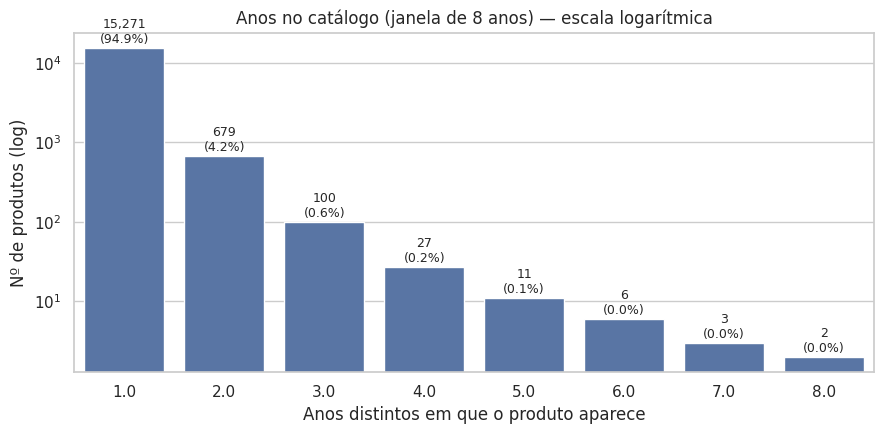

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

dist = df_modelo.groupBy("label").count().orderBy("label").toPandas()
dist["%"] = (dist["count"] / dist["count"].sum() * 100).round(2)
display(dist)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=dist, x="label", y="count", color="#4C72B0", ax=ax)
ax.set_yscale("log")
for i, r in dist.iterrows():
    ax.text(i, r["count"] * 1.15, f'{int(r["count"]):,}\n({r["%"]:.1f}%)', ha="center", fontsize=9)
ax.set_title(f"Anos no catálogo (janela de {JANELA_ANOS} anos) — escala logarítmica")
ax.set_xlabel("Anos distintos em que o produto aparece"); ax.set_ylabel("Nº de produtos (log)")
plt.tight_layout(); plt.show()

Leitura: a imensa maioria dos produtos (~95%) aparece em um único ano. A variável alvo é muito assimétrica. Assim, um modelo "naive" que prevê sempre a média já tende a acertar bastante.

Análise exploratória: as features se relacionam com o alvo?
Taxa de recorrência (% de produtos em 2+ anos) segundo algumas características. Isso dá uma primeira ideia do sinal disponível antes de treinar qualquer modelo.

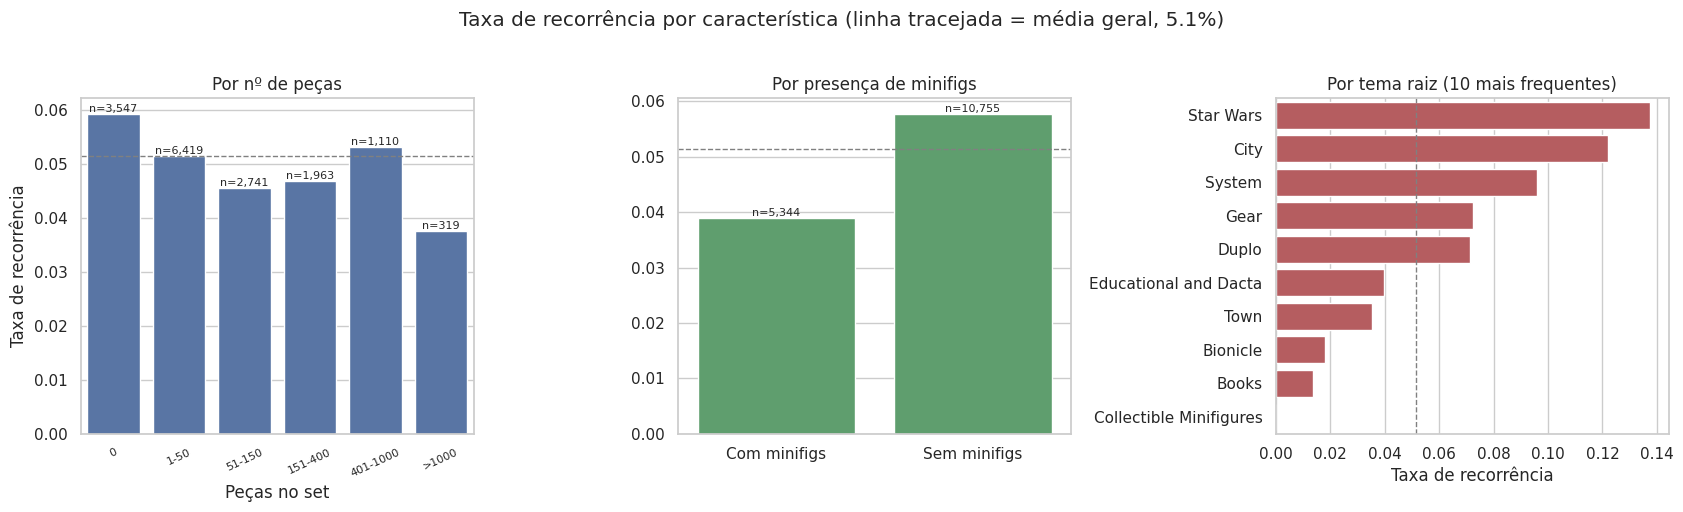

In [80]:
pdf = df_modelo.select("tema_raiz", "log_num_parts", "num_minifigs", "sem_pecas", "recorreu", "nome_n_palavras").toPandas()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) por tamanho do set (faixas de peças, em escala real)
pdf["faixa_pecas"] = pd.cut(np.expm1(pdf["log_num_parts"]), [-1, 0, 50, 150, 400, 1000, 1e6],
                            labels=["0", "1-50", "51-150", "151-400", "401-1000", ">1000"])
t = pdf.groupby("faixa_pecas", observed=True)["recorreu"].agg(["mean", "size"]).reset_index()
sns.barplot(data=t, x="faixa_pecas", y="mean", color="#4C72B0", ax=axes[0])
axes[0].set_title("Por nº de peças"); axes[0].set_xlabel("Peças no set"); axes[0].set_ylabel("Taxa de recorrência")
axes[0].tick_params(axis="x", labelsize=8, rotation=25)
for i, r in t.iterrows(): axes[0].text(i, r["mean"], f'n={int(r["size"]):,}', ha="center", va="bottom", fontsize=8)

# (b) por presença de minifigs
pdf["tem_minifig"] = np.where(pdf["num_minifigs"] > 0, "Com minifigs", "Sem minifigs")
t = pdf.groupby("tem_minifig")["recorreu"].agg(["mean", "size"]).reset_index()
sns.barplot(data=t, x="tem_minifig", y="mean", color="#55A868", ax=axes[1])
axes[1].set_title("Por presença de minifigs"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
for i, r in t.iterrows(): axes[1].text(i, r["mean"], f'n={int(r["size"]):,}', ha="center", va="bottom", fontsize=8)

# (c) por tema raiz (10 maiores)
top10 = pdf["tema_raiz"].value_counts().head(10).index
t = (pdf[pdf["tema_raiz"].isin(top10)].groupby("tema_raiz")["recorreu"].mean()
       .sort_values(ascending=False).reset_index())
sns.barplot(data=t, y="tema_raiz", x="recorreu", color="#C44E52", ax=axes[2])
axes[2].set_title("Por tema raiz (10 mais frequentes)"); axes[2].set_xlabel("Taxa de recorrência"); axes[2].set_ylabel("")

taxa_geral = pdf["recorreu"].mean()
for ax in axes[:2]: ax.axhline(taxa_geral, color="gray", ls="--", lw=1)
axes[2].axvline(taxa_geral, color="gray", ls="--", lw=1)
fig.suptitle(f"Taxa de recorrência por característica (linha tracejada = média geral, {taxa_geral:.1%})", y=1.02)
plt.tight_layout(); plt.show()

Leitura: A recorrência, nossa proxy de sucesso, não parece ter uma relação com o números de peças do set, mas parece que a ausência de minifigs está relacionada e alguns temas também (Star Wars é o tema de maior recorrência).

2.3 Preparação para o modelo
Split treino × teste
Treinamos no passado e testamos no futuro:

Treino: produtos lançados até ANO_CORTE_TREINO (2013)
Teste: produtos lançados depois (2014 até o último ano elegível)
Agrupando temas raros
Os temas raiz mais frequentes no treino (TOP_N_TEMAS) são mantidos; os demais viram "Outros".

In [81]:
df_treino = df_modelo.filter(F.col("ano_lancamento") <= ANO_CORTE_TREINO)
df_teste  = df_modelo.filter(F.col("ano_lancamento") >  ANO_CORTE_TREINO)

# Top N temas, calculados apenas no treino
temas_top = [r["tema_raiz"] for r in
             df_treino.groupBy("tema_raiz").count().orderBy(F.desc("count")).limit(TOP_N_TEMAS).collect()]

def agrupa_tema(df):
    return df.withColumn("tema_grupo",
                         F.when(F.col("tema_raiz").isin(temas_top), F.col("tema_raiz")).otherwise(F.lit("Outros")))

df_treino, df_teste = agrupa_tema(df_treino).cache(), agrupa_tema(df_teste).cache()

for nome, d in [("Treino", df_treino), ("Teste", df_teste)]:
    r = d.agg(F.count("*").alias("n"), F.mean("recorreu").alias("taxa_rec"), F.mean("label").alias("alvo_medio"),
              F.min("ano_lancamento").alias("de"), F.max("ano_lancamento").alias("ate")).collect()[0]
    print(f"{nome:6s}: {r['n']:>6,} produtos | lançados {int(r['de'])}–{int(r['ate'])} | "
          f"alvo médio = {r['alvo_medio']:.3f} | recorrência = {r['taxa_rec']:.2%}")
print("\nTemas mantidos:", temas_top)

Treino: 11,259 produtos | lançados 1949–2013 | alvo médio = 1.071 | recorrência = 5.52%
Teste :  4,840 produtos | lançados 2014–2018 | alvo médio = 1.056 | recorrência = 4.26%

Temas mantidos: ['Gear', 'Duplo', 'Educational and Dacta', 'Town', 'System', 'Service Packs', 'Bionicle', 'Star Wars', 'Technic', 'Creator', 'Space', 'Books', 'Racers', 'City', 'Castle', 'Collectible Minifigures', 'Universal Building Set', 'Train', 'Sports', 'Seasonal', 'LEGO Brand Store', 'Bulk Bricks', 'Legoland', 'Primo', 'Make & Create']


Pré-processamento
O tema é categórico e cada modelo o trata de um jeito:

Regressão linear precisa de números: usamos One-Hot Encoding.
Árvore de decisão consegue trabalhar com a categoria diretamente: usamos só o índice.

[ ]


In [82]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.regression import LinearRegression, DecisionTreeRegressor
from pyspark.ml.evaluation import RegressionEvaluator, BinaryClassificationEvaluator

indexador = StringIndexer(inputCol="tema_grupo", outputCol="tema_idx", handleInvalid="keep")
codificador = OneHotEncoder(inputCols=["tema_idx"], outputCols=["tema_ohe"], handleInvalid="keep")

# Regressão linear: tema one-hot + numéricas
montador_lr = VectorAssembler(inputCols=["tema_ohe"] + FEATURES_NUM, outputCol="features")
# Árvore: índice do tema (categórico) + numéricas
montador_dt = VectorAssembler(inputCols=["tema_idx"] + FEATURES_NUM, outputCol="features")

def nomes_das_features(df, coluna="features"):
    # Recupera o nome de cada posição do vetor de features a partir dos metadados do Spark
    attrs = df.schema[coluna].metadata["ml_attr"]["attrs"]
    todos = [a for grupo in attrs.values() for a in grupo]
    return [a["name"] for a in sorted(todos, key=lambda a: a["idx"])]

print("Features numéricas:", FEATURES_NUM)

Features numéricas: ['ano_lancamento', 'log_num_parts', 'sem_pecas', 'n_variantes_lancamento', 'nome_n_palavras']


**2.4 Modelagem**

Métricas

* RMSE / MAE: erro médio em "anos".
* R²: fração da variância explicada.
* AUC: mede o quanto o modelo separa quem reaparece de quem não reaparece (0,5 = acaso; 1,0 = perfeito).

**Baseline**
O ponto de comparação mais simples: prever sempre a média do treino. Qualquer modelo precisa ganhar disso para ter valor.

In [83]:
av_rmse = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="rmse")
av_mae  = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="mae")
av_r2   = RegressionEvaluator(labelCol="label", predictionCol="prediction", metricName="r2")
av_auc  = BinaryClassificationEvaluator(labelCol="recorreu", rawPredictionCol="prediction", metricName="areaUnderROC")

def avaliar(pred, nome):
    # Calcula as métricas no conjunto de teste e devolve um dicionário (para montar a tabela comparativa)
    pred = pred.withColumn("prediction", F.greatest(F.col("prediction"), F.lit(1.0)))   # piso de 1 ano
    # lift no top 10%: ordena pelo score e compara a taxa de recorrência do topo com a taxa geral
    p = pred.select("prediction", "recorreu").toPandas().sort_values("prediction", ascending=False, kind="mergesort")
    topo = p.head(int(len(p) * 0.10))["recorreu"].mean()
    return {"modelo": nome, "RMSE": av_rmse.evaluate(pred), "MAE": av_mae.evaluate(pred),
            "R2": av_r2.evaluate(pred), "AUC": av_auc.evaluate(pred), "Lift_top10": topo / p["recorreu"].mean()}

# Baseline: média do alvo no treino aplicada a todo o teste
media_treino = df_treino.agg(F.mean("label")).collect()[0][0]
pred_base = df_teste.withColumn("prediction", F.lit(media_treino))
res_base = avaliar(pred_base, "Baseline (média do treino)")
res_base["AUC"], res_base["Lift_top10"] = 0.5, 1.0   # previsão constante => sem ranqueamento (AUC = 0,5 por definição)
print(f"Média do alvo no treino = {media_treino:.4f} anos")
display(pd.DataFrame([res_base]).round(4))

Média do alvo no treino = 1.0705 anos


,modelo,RMSE,MAE,R2,AUC,Lift_top10
0,Baseline (média do treino),0.3213,0.1207,-0.002,0.5,1.0


Modelo 1 — Regressão Linear (regularizada)
Como temos features correlacionadas entre si (por exemplo, log_num_parts e pecas_distintas), usamos regularização Ridge.

O Spark já padroniza as features (standardization=True).



In [84]:
# Hiperparâmetros fixos: Ridge (elasticNetParam=0) com regularização moderada
lr = LinearRegression(featuresCol="features", labelCol="label", standardization=True, maxIter=200,
                      regParam=0.1, elasticNetParam=0.0)
modelo_lr = Pipeline(stages=[indexador, codificador, montador_lr, lr]).fit(df_treino)

melhor_lr = modelo_lr.stages[-1]
pred_lr = modelo_lr.transform(df_teste)
res_lr = avaliar(pred_lr, "Regressão Linear")
display(pd.DataFrame([res_lr]).round(4))

,modelo,RMSE,MAE,R2,AUC,Lift_top10
0,Regressão Linear,0.3177,0.1022,0.0202,0.773,2.8641


**Modelo 2 — Árvore de Decisão**

A árvore captura não linearidades e interações sem precisar explicitá-las. Controlamos overfitting com maxDepth=5 e minInstancesPerNode=30.

In [85]:
# Hiperparâmetros fixos: profundidade moderada e folhas com pelo menos 30 produtos (limita o overfitting)
dt = DecisionTreeRegressor(featuresCol="features", labelCol="label", maxBins=32, seed=SEMENTE,
                           maxDepth=5, minInstancesPerNode=30)
modelo_dt = Pipeline(stages=[indexador, montador_dt, dt]).fit(df_treino)

melhor_dt = modelo_dt.stages[-1]
pred_dt = modelo_dt.transform(df_teste)
res_dt = avaliar(pred_dt, "Árvore de Decisão")
display(pd.DataFrame([res_dt]).round(4))

,modelo,RMSE,MAE,R2,AUC,Lift_top10
0,Árvore de Decisão,0.3192,0.1058,0.0114,0.7232,2.6699


**2.5 Avaliação e interpretação**

Comparação dos modelos no conjunto de teste (lançamentos de 2014 em diante)


In [86]:
tabela = pd.DataFrame([res_base, res_lr, res_dt]).set_index("modelo")
display(tabela.round(4))

# Ganho relativo do RMSE sobre o baseline
for nome in ["Regressão Linear", "Árvore de Decisão"]:
    ganho = (1 - tabela.loc[nome, "RMSE"] / tabela.loc["Baseline (média do treino)", "RMSE"]) * 100
    print(f"{nome:20s}: RMSE {ganho:+.2f}% vs. baseline")

,RMSE,MAE,R2,AUC,Lift_top10
modelo,,,,,
Baseline (média do treino),0.3213,0.1207,-0.0020,0.5000,1.0000
Regressão Linear,0.3177,0.1022,0.0202,0.7730,2.8641
Árvore de Decisão,0.3192,0.1058,0.0114,0.7232,2.6699


Regressão Linear    : RMSE +1.11% vs. baseline
Árvore de Decisão   : RMSE +0.67% vs. baseline


**O que cada modelo "aprendeu"?**

* Regressão linear: coeficientes (com features padronizadas, o sinal indica a direção e o tamanho indica a força relativa).

* Árvore de decisão: importância de cada feature, isto é, o quanto ela contribuiu para reduzir o erro nas divisões.


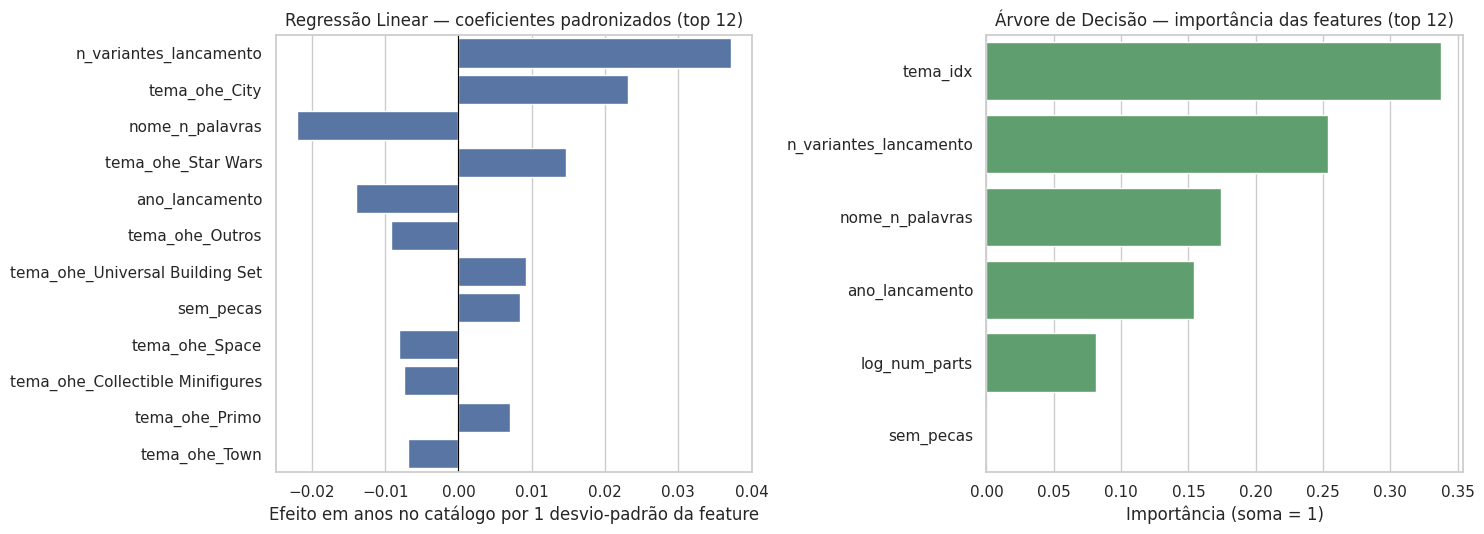

,feature,coeficiente,coef_padronizado
0,n_variantes_lancamento,0.1304,0.0371
1,tema_ohe_City,0.1525,0.0231
2,nome_n_palavras,-0.0107,-0.0220
3,tema_ohe_Star Wars,0.0875,0.0147
4,ano_lancamento,-0.0011,-0.0140
5,tema_ohe_Outros,-0.0230,-0.0093
6,tema_ohe_Universal Building Set,0.0643,0.0093
7,sem_pecas,0.0221,0.0084
8,tema_ohe_Space,-0.0501,-0.0081
9,tema_ohe_Collectible Minifigures,-0.0518,-0.0075


,feature,importancia
0,tema_idx,0.3373
1,n_variantes_lancamento,0.2538
2,nome_n_palavras,0.1739
3,ano_lancamento,0.1538
4,log_num_parts,0.0813
5,sem_pecas,0.0000


In [87]:
# --- Regressão linear: coeficientes das 12 features de maior magnitude
df_ref_lr = modelo_lr.transform(df_teste.limit(5))
nomes_lr  = nomes_das_features(df_ref_lr)
coefs = pd.DataFrame({"feature": nomes_lr, "coeficiente": melhor_lr.coefficients.toArray()})
# Em padronização interna, o Spark devolve coeficientes na escala original; multiplicamos pelo desvio-padrão
# da feature no treino para obter coeficientes comparáveis entre features.
X_tr = modelo_lr.transform(df_treino).select("features").toPandas()["features"].apply(lambda v: v.toArray())
desvios = np.vstack(X_tr.values).std(axis=0)
coefs["coef_padronizado"] = coefs["coeficiente"] * desvios
coefs = coefs.reindex(coefs["coef_padronizado"].abs().sort_values(ascending=False).index).head(12)

# --- Árvore: importâncias
df_ref_dt = modelo_dt.transform(df_teste.limit(5))
nomes_dt  = nomes_das_features(df_ref_dt)
imps = pd.DataFrame({"feature": nomes_dt, "importancia": melhor_dt.featureImportances.toArray()})
imps = imps.sort_values("importancia", ascending=False).head(12)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=coefs, y="feature", x="coef_padronizado", color="#4C72B0", ax=axes[0])
axes[0].axvline(0, color="black", lw=.8); axes[0].set_title("Regressão Linear — coeficientes padronizados (top 12)")
axes[0].set_xlabel("Efeito em anos no catálogo por 1 desvio-padrão da feature"); axes[0].set_ylabel("")
sns.barplot(data=imps, y="feature", x="importancia", color="#55A868", ax=axes[1])
axes[1].set_title("Árvore de Decisão — importância das features (top 12)")
axes[1].set_xlabel("Importância (soma = 1)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

display(coefs.round(4).reset_index(drop=True))
display(imps.round(4).reset_index(drop=True))

### 2.6 O que encontramos

A capacidade de previsão dos modelos foi modesta. O baseline, que prevê a média do alvo no conjunto de treino, obteve RMSE de aproximadamente 0,3213 ano. A Regressão Linear reduziu esse erro para 0,3177, uma melhoria de cerca de 1,11%, enquanto a Árvore de Decisão alcançou RMSE de 0,3192, uma melhoria de aproximadamente 0,65%.

A Regressão Linear apresentou os melhores resultados neste teste, com AUC de 0,7730, contra 0,7232 da Árvore de Decisão. Isso indica melhor capacidade de distinguir produtos que reaparecem no catálogo daqueles que não reaparecem, segundo a definição adotada no projeto. Entretanto, os valores baixos de R² (0,0202 e 0,0114, respectivamente) mostram que os modelos explicam apenas uma pequena parcela da variação da quantidade de anos no catálogo.

A distribuição do alvo é bastante assimétrica: aproximadamente 95% dos produtos aparecem em apenas um ano da janela observada. Essa concentração limita a capacidade de explicar a variação do alvo e ajuda a contextualizar os resultados modestos.

As visualizações dos coeficientes da Regressão Linear e da importância das variáveis na Árvore de Decisão permitem investigar quais características estão mais associadas às previsões. Contudo, essas associações não demonstram causalidade, e a interpretação deve considerar que as variáveis derivadas de inventários posteriores ao lançamento foram retiradas do conjunto de entrada para reduzir o risco de vazamento temporal.

Por fim, a variável-alvo representa a recorrência no catálogo, e não vendas, receita ou sucesso comercial diretamente. Portanto, os resultados devem ser entendidos como uma análise exploratória da recorrência dos produtos LEGO.